
🧩 MedSSL-3D v0.8 — Mode B: Multi-seed statistical baseline + SE Attention (ResidualDecoder3D)

🧪 ENVIRONMENT REPORT
Python      : 3.10.20
PyTorch     : 2.7.1+cu118
MONAI       : 1.4.0
NumPy       : 1.26.4
CUDA avail. : True
GPU         : NVIDIA GeForce RTX 3050 6GB Laptop GPU
GPU memory  : 6.0 GB
Device used : cuda
Run mode    : segmentation

📂 DATA_ROOT : D:/MedSSL/MICCAI_BraTS2020_TrainingData
📂 MODALITY  : flair
📂 Seg checkpoints -> D:/MedSSL/MedSSL_Results\checkpoints\segmentation
📂 Seg logs        -> D:/MedSSL/MedSSL_Results\logs\segmentation
📂 v0.8 checkpoints -> D:/MedSSL/MedSSL_Results\outputs\v0_8\checkpoints
📂 v0.8 logs        -> D:/MedSSL/MedSSL_Results\outputs\v0_8\logs
📂 v0.8 USE_CHANNEL_SE_ATTENTION = True
🔒 Seed set to 42

🔍 DATA SANITY CHECK (Mode B — Segmentation)
✅ Directory exists: D:/MedSSL/MICCAI_BraTS2020_TrainingData
✅ Found 369 'flair' file(s)
⚠️ 1 image file(s) had no matching segmentation mask and were skipped.
✅ Matched 368 (image, mask) pair(s)
📄 First pair

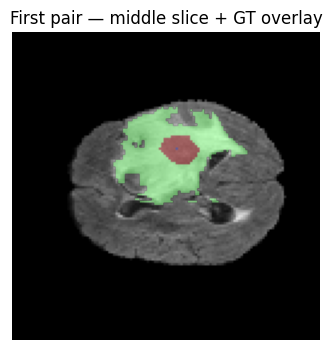

✅ Middle slice + ground-truth overlay displayed above.

✅ SEGMENTATION SANITY CHECK PASSED.


📁 PATIENT-LEVEL TRAIN/VAL/TEST SPLIT (v0.7-A)
✅ Found existing split file: D:/MedSSL/MedSSL_Results\data_split_v1.json
📌 Loaded split (NOT recomputed) — ensures identical patients across v0.7-A / v0.7-B / v0.8 / v0.9.
📊 Train: 258 | Val: 55 | Test: 55 (reserved, untouched in v0.7-A)
🔒 Test set will NOT be evaluated or visualized anywhere in v0.7-A — reserved for v1.0.
Encoder path: D:/MedSSL/MedSSL_Results\checkpoints\encoder.pth
Exists? True

🌱 v0.8 — Training seed 42
🔒 Seed set to 42
⚠️ Strict encoder load failed (Error(s) in loading state_dict for ResNet3D:
	size mismatch for conv1.weight: copying a param with shape torch.Size([64, 1, 7, 7, 7]) from checkpoint, the shape in current model is torch.Size([64, 4, 7, 7, 7]).); retrying with strict=False.
⚠️ Skipping incompatible-shape keys (kept at random init): ['conv1.weight']
⚠️ Loaded with mismatches — missing: ['conv1.weight'], unexpected: 

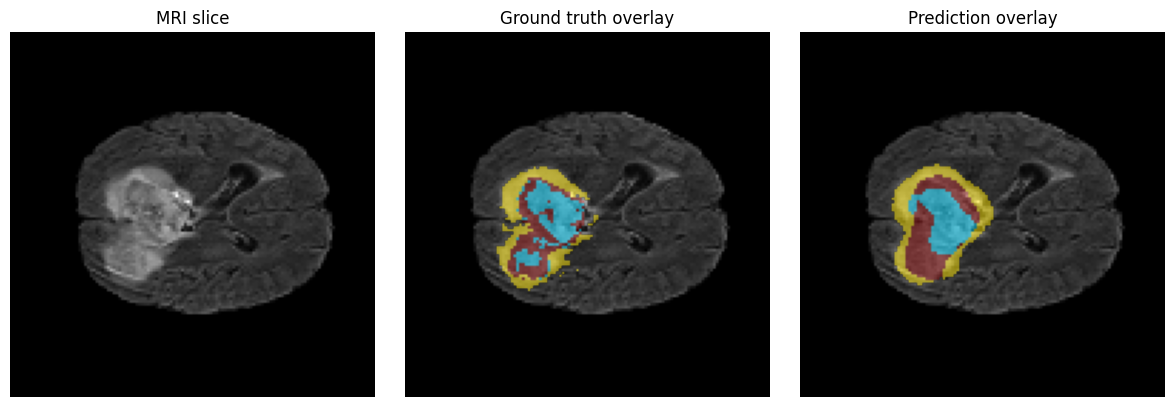

🏁 Seed 42 FINAL (best checkpoint, epoch 22) — Dice: 0.4537 | IoU: 0.3324 | WT: 0.7628 | TC: 0.6525 | ET: 0.5342

🎛️ v0.8 — Channel Attention logging (seed 42)
🎛️ Seed 42 channel attention — overall mean=0.5034 | overall variance=0.003794
💾 Channel attention weights saved to D:/MedSSL/MedSSL_Results\outputs\v0_8\attention\channel_attention_weights_seed_42.csv

🧪 v0.8 — Post-hoc Modality Ablation (seed 42)
🧪 Seed 42 modality ablation (baseline Dice=0.4537):
   FLAIR 34%  (drop=0.2114)
   T1    28%  (drop=0.1758)
   T1CE  29%  (drop=0.1830)
   T2    9%  (drop=0.0530)
💾 Modality ablation saved to D:/MedSSL/MedSSL_Results\outputs\v0_8\csv\modality_ablation_seed_42.csv

🔬 v0.8 — Linear Probe sanity check (seed 42)
✅ Loaded 369 patient grade label(s) from D:/MedSSL/MICCAI_BraTS2020_TrainingData\name_mapping.csv
⚖️ Class imbalance detected (HGG=205, LGG=53) — using weighted CrossEntropy.
   Linear Probe epoch 1/15 — loss=0.8043
   Linear Probe epoch 2/15 — loss=0.6794
   Linear Probe epoch 3/1

KeyboardInterrupt: 

In [1]:
# ==============================================================================
# MedSSL-3D v0.8-B
# Self-Supervised 3D Medical Representation Learning (SimCLR) + a U-Net-style
# residual segmentation decoder with deep supervision.
#
# v0.7-A SCOPE (per project roadmap): "Single-modality baseline stabilization".
# This version does NOT touch the architecture (Encoder/Decoder/Skip
# connections/Deep Supervision are exactly v0.6, byte-for-byte). It only
# makes the SEGMENTATION TRAINING PROTOCOL statistically trustworthy:
#   1. Patient-level Train/Val/Test split (70/15/15), persisted to JSON and
#      reloaded on every subsequent run so v0.7-B/v0.8/v0.9 use the SAME
#      patients. The Test set is loaded/counted only — never evaluated here.
#   2. Multi-seed (3 seeds) training: each seed re-seeds everything, reloads
#      the SSL encoder fresh, reinitializes the decoder from scratch, trains
#      independently, and reports its own final metrics. Mean +/- Std across
#      seeds is the reported v0.7-A baseline number.
#   3. NUM_EPOCHS_SEG increased 20 -> 45, CosineAnnealingLR added.
#   4. Checkpoint selection now uses a 3-epoch moving average of Val Dice
#      instead of a single noisy epoch value.
#   5. BraTS-style region metrics (WT / TC / ET Dice) added on top of the
#      existing 4-class Dice/IoU, computed on the already-remapped {0,1,2,3}
#      labels.
#   6. Logging extended (val loss, WT/TC/ET, current LR) but keeps v0.6's
#      emoji/logging style.
#   7. All new knobs centralized in Config.
#
# EVERYTHING IN MODE A (SimCLR pretraining) IS REPRODUCED UNCHANGED FROM v0.6.
#
# Single Google Colab / Jupyter cell — single continuous run.
#
# ONLY LINE YOU SHOULD NEED TO EDIT: Config.DATA_ROOT, below.
# ==============================================================================

# ==============================================================================
# NEW in v0.8 — Shared Encoder Feature Attention + Linear Probe Sanity Check
#
# v0.8 SCOPE (per project roadmap): single independent variable = Channel-wise
# SE Attention applied to the encoder bottleneck (l4) only. Everything else
# added below is evaluation-only and never touches training/optimization:
#   1. NEW: SEChannelAttention3D — applied ONLY to l4 inside SegmentationModel3D,
#      gated by Config.USE_CHANNEL_SE_ATTENTION (default True). When False,
#      forward() behaves byte-for-byte like v0.7-B.
#   2. NEW: post-training Channel Attention logging (mean weight per channel).
#   3. NEW: post-hoc Modality Ablation (zero-mask each of FLAIR/T1/T1CE/T2,
#      measure Dice drop) — evaluation only, no trainable parameters.
#   4. NEW: Linear Probe sanity check (Linear(512->2) on the frozen, already
#      fine-tuned v0.8 encoder) using HGG/LGG grades from name_mapping.csv.
#   5. NEW: dedicated v0.8 output root (outputs/v0_8/...) — nothing in
#      previous version folders is ever overwritten.
#
# The ResNet3D encoder, ResidualDecoder3D, losses, dataset, split logic, and
# checkpoint-selection strategy are all UNCHANGED from v0.7-B.
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. Install dependencies
#    (This '!' line is Jupyter/Colab notebook-cell syntax. If you ever run this
#    file as a plain .py script instead of a notebook cell, remove this line
#    and install the packages beforehand with a normal `pip install` command.)
# ------------------------------------------------------------------------------
!pip install -q torch torchvision monai nibabel numpy tqdm matplotlib

# ------------------------------------------------------------------------------
# 2. Imports
# ------------------------------------------------------------------------------
import os
import glob
import json
import csv
import time
import random
import logging
import platform
import re                      # NEW in v0.8 — patient-ID extraction for Linear Probe grade lookup
from typing import Tuple, List, Optional, Union

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import monai
from monai.transforms import (
    Compose, LoadImage, EnsureChannelFirst, Resize, NormalizeIntensity,
    RandFlip, RandRotate90, RandGaussianNoise, RandScaleIntensity, RandShiftIntensity,
)

import matplotlib.pyplot as plt
from tqdm import tqdm

# ------------------------------------------------------------------------------
# 3. Logging
# ------------------------------------------------------------------------------
logging.basicConfig(level=logging.INFO, format='%(message)s')
logger = logging.getLogger('MedSSL-3D')


def log_section(title: str) -> None:
    logger.info("\n" + "=" * 80)
    logger.info(title)
    logger.info("=" * 80)


# ------------------------------------------------------------------------------
# 4. Config
# ------------------------------------------------------------------------------
class Config:
    SEED = 42
    DEVICE = 'cuda'

    # ---- Shared by both modes ----
    IMG_SIZE = (128, 128, 64)     # (H, W, D)
    NUM_WORKERS = 0                # keep 0 — safest choice on Colab

    # >>> THE ONLY LINE YOU SHOULD NEED TO EDIT <<<
    # Moved off the OneDrive-synced C:\Users\...\Desktop path onto a local D:
    # drive — OneDrive "Files On-Demand" placeholders were the root cause of
    # the ~6x per-epoch slowdown diagnosed earlier (each Train file had to be
    # fetched from the cloud on first read, serially, since NUM_WORKERS=0).
    DATA_ROOT = 'D:/MedSSL/MICCAI_BraTS2020_TrainingData'
    MODALITY = 'flair'            # 't1', 't1ce', 't2', or 'flair'

    # ---- Mode switch ----
    MODE = 'segmentation'          # 'simclr' (Mode A, = v0.4/v0.5/v0.6 unchanged) or 'segmentation' (Mode B)

    # ---- Mode A: SimCLR pretraining (identical defaults to v0.4/v0.5/v0.6) ----
    BATCH_SIZE = 8
    PROJECTION_DIM = 128
    TEMPERATURE = 0.5
    LR = 1e-4
    NUM_EPOCHS = 20

    # ---- Output directories ----
    # Also moved to the same local D: drive as DATA_ROOT, so checkpoints/logs
    # are never re-exposed to OneDrive sync either.
    DESKTOP_BASE = 'D:/MedSSL/MedSSL_Results'
    CHECKPOINT_DIR = os.path.join(DESKTOP_BASE, 'checkpoints')
    LOG_DIR = os.path.join(DESKTOP_BASE, 'logs')
    SEG_CHECKPOINT_DIR = os.path.join(DESKTOP_BASE, 'checkpoints', 'segmentation')
    SEG_LOG_DIR = os.path.join(DESKTOP_BASE, 'logs', 'segmentation')

    # ---- Mode B: Segmentation (dataset/loss/metrics core unchanged from v0.5/v0.6) ----
    NUM_SEG_CLASSES = 4            # background, NCR/NET, edema, enhancing (BraTS label 4 -> 3)
    BATCH_SIZE_SEG = 2              # 3D volumes are memory-heavy; lower this further if you hit OOM
    LR_SEG = 1e-4
    USE_PRETRAINED_ENCODER = True
    PRETRAINED_ENCODER_PATH = os.path.join(CHECKPOINT_DIR, 'encoder.pth')   # produced by Mode A

    # ---- Mode B, v0.6: deep-supervision auxiliary loss weight ----
    # Applied to each of the two auxiliary heads in ResidualDecoder3D.
    # Main loss keeps weight 1.0, exactly as v0.5's single-output loss did.
    AUX_LOSS_WEIGHT = 0.3

    # ==========================================================================
    # ---- Mode B, NEW IN v0.7-A: statistical baseline stabilization ----
    # ==========================================================================
    # Epochs increased from v0.6's 20 into the 40-50 range requested for v0.7-A.
    NUM_EPOCHS_SEG = 25

    # Independent training seeds. Each seed retrains the segmentation model
    # from scratch (fresh SSL encoder reload + fresh decoder init) so the
    # final reported metric is a Mean +/- Std across genuinely separate runs,
    # not 3 samples from the same noisy trajectory.
    SEEDS = [42, 123]

    # Patient-level 3-way split fractions (must sum to 1.0).
    TRAIN_FRACTION = 0.70
    VAL_FRACTION = 0.15
    TEST_FRACTION = 0.15

    # Split is computed once and persisted here. If this file exists on a
    # later run, it is LOADED (never recomputed), guaranteeing v0.7-B, v0.8,
    # v0.9, ... all train/val/test on the exact same patients as v0.7-A.
    SPLIT_FILE_PATH = os.path.join(DESKTOP_BASE, 'data_split_v1.json')

    # CosineAnnealingLR — simplest scheduler compatible with the existing
    # per-epoch Adam loop. T_max is set to NUM_EPOCHS_SEG at scheduler
    # construction time (one full cosine cycle per training run).
    SCHEDULER_TYPE = 'cosine'
    SCHEDULER_ETA_MIN = 1e-6

    # Best-checkpoint selection: moving average window size (epochs).
    # Per spec: starting once >= this many epochs have completed, compute
    # mean(val_dice[e-2], val_dice[e-1], val_dice[e]) and save whenever it's
    # a new best. NOT a weight average — only used as the selection metric.
    MOVING_AVG_WINDOW = 3

    # Where the final multi-seed Mean +/- Std summary table is written.
    SEG_SUMMARY_CSV = os.path.join(SEG_LOG_DIR, 'v0_7a_multiseed_summary.csv')

    # ==========================================================================
    # ---- Mode B, NEW IN v0.8: Channel-wise SE Attention (single independent
    # variable) + versioned outputs + Modality Ablation + Linear Probe.
    # ==========================================================================
    # The ONLY architectural change in v0.8. When False, SegmentationModel3D's
    # forward() is byte-for-byte identical to v0.7-B (see Task 1 of the spec).
    USE_CHANNEL_SE_ATTENTION = True                                    # NEW in v0.8
    SE_REDUCTION_RATIO = 16                                            # NEW in v0.8

    # Dedicated v0.8 output root — v0.8 must NEVER overwrite v0.7-A/v0.7-B
    # outputs, which all live directly under DESKTOP_BASE/checkpoints and
    # DESKTOP_BASE/logs above.
    VERSION_ROOT_V0_8 = os.path.join(DESKTOP_BASE, 'outputs', 'v0_8')          # NEW in v0.8
    V0_8_CHECKPOINT_DIR = os.path.join(VERSION_ROOT_V0_8, 'checkpoints')      # NEW in v0.8
    V0_8_LOG_DIR = os.path.join(VERSION_ROOT_V0_8, 'logs')                    # NEW in v0.8
    V0_8_CSV_DIR = os.path.join(VERSION_ROOT_V0_8, 'csv')                     # NEW in v0.8
    V0_8_ATTENTION_DIR = os.path.join(VERSION_ROOT_V0_8, 'attention')         # NEW in v0.8
    V0_8_LINEAR_PROBE_DIR = os.path.join(VERSION_ROOT_V0_8, 'linear_probe')   # NEW in v0.8

    # NEW in v0.8, Task 3 — Linear Probe sanity check.
    NAME_MAPPING_CSV_PATH = os.path.join(DATA_ROOT, 'name_mapping.csv')       # NEW in v0.8
    LINEAR_PROBE_EPOCHS = 15                                                  # NEW in v0.8
    LINEAR_PROBE_LR = 1e-3                                                    # NEW in v0.8
    LINEAR_PROBE_BATCH_SIZE = 4                                               # NEW in v0.8

    # NEW in v0.8 — where the v0.8 multi-seed Mean +/- Std summary table is
    # written. Kept separate from v0.7-A's SEG_SUMMARY_CSV above.
    SEG_SUMMARY_CSV_V0_8 = os.path.join(V0_8_CSV_DIR, 'v0_8_multiseed_summary.csv')  # NEW in v0.8

    @classmethod
    def setup_dirs(cls) -> None:
        os.makedirs(cls.CHECKPOINT_DIR, exist_ok=True)
        os.makedirs(cls.LOG_DIR, exist_ok=True)
        os.makedirs(cls.SEG_CHECKPOINT_DIR, exist_ok=True)
        os.makedirs(cls.SEG_LOG_DIR, exist_ok=True)
        # NEW in v0.8: dedicated version root, never touches the dirs above.
        os.makedirs(cls.V0_8_CHECKPOINT_DIR, exist_ok=True)
        os.makedirs(cls.V0_8_LOG_DIR, exist_ok=True)
        os.makedirs(cls.V0_8_CSV_DIR, exist_ok=True)
        os.makedirs(cls.V0_8_ATTENTION_DIR, exist_ok=True)
        os.makedirs(cls.V0_8_LINEAR_PROBE_DIR, exist_ok=True)

    @classmethod
    def to_dict(cls) -> dict:
        return {
            k: (list(v) if isinstance(v, tuple) else v)
            for k, v in vars(cls).items()
            if not k.startswith('_') and not callable(v) and not isinstance(v, classmethod)
        }


# ------------------------------------------------------------------------------
# 5. Environment report — helps diagnose Colab / library-version drift
# ------------------------------------------------------------------------------
def print_environment_report() -> None:
    log_section("🧪 ENVIRONMENT REPORT")
    logger.info(f"Python      : {platform.python_version()}")
    logger.info(f"PyTorch     : {torch.__version__}")
    logger.info(f"MONAI       : {monai.__version__}")
    logger.info(f"NumPy       : {np.__version__}")
    logger.info(f"CUDA avail. : {torch.cuda.is_available()}")
    if torch.cuda.is_available():
        logger.info(f"GPU         : {torch.cuda.get_device_name(0)}")
        total_mem = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
        logger.info(f"GPU memory  : {total_mem:.1f} GB")
    logger.info(f"Device used : {Config.DEVICE}")
    logger.info(f"Run mode    : {Config.MODE}")


# ------------------------------------------------------------------------------
# 6. Seed
# ------------------------------------------------------------------------------
def set_seed(seed: int = Config.SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    logger.info(f"🔒 Seed set to {seed}")


# ------------------------------------------------------------------------------
# 7. Base loading transforms (deterministic — no randomness) — UNCHANGED
# ------------------------------------------------------------------------------
def build_base_transform(img_size: Tuple[int, int, int]) -> Compose:
    """For MRI volumes: trilinear resize preserves intensity gradients."""
    return Compose([
        LoadImage(image_only=True),
        EnsureChannelFirst(),
        Resize(spatial_size=img_size, mode='trilinear'),
    ])


def build_mask_transform(img_size: Tuple[int, int, int]) -> Compose:
    """For segmentation masks: nearest-neighbor resize keeps integer class labels intact."""
    return Compose([
        LoadImage(image_only=True),
        EnsureChannelFirst(),
        Resize(spatial_size=img_size, mode='nearest'),
    ])


# ------------------------------------------------------------------------------
# 8. Mode A — Data Sanity Check (unchanged from v0.4/v0.5/v0.6; stops on failure)
# ------------------------------------------------------------------------------
def run_data_sanity_check(data_root: str, modality: str,
                           img_size: Tuple[int, int, int]) -> List[str]:
    """
    Pre-flight check for the SimCLR (Mode A) data pipeline:
      - directory exists
      - files for the chosen modality are found
      - first file loads, with sane shape / dtype / min / max
      - no NaN / Inf
      - a middle slice is displayed for visual confirmation
    Raises SystemExit with a clear message on any failure.
    """
    log_section("🔍 DATA SANITY CHECK (Mode A — SimCLR)")

    if not os.path.isdir(data_root):
        raise SystemExit(
            f"❌ DATA_ROOT does not exist: '{data_root}'\n"
            f"   -> Update Config.DATA_ROOT to the folder where you downloaded BraTS."
        )
    logger.info(f"✅ Directory exists: {data_root}")

    pattern = os.path.join(data_root, '**', f'*{modality}*.nii*')
    image_paths = sorted(glob.glob(pattern, recursive=True))

    if len(image_paths) == 0:
        raise SystemExit(
            f"❌ No files matching modality '{modality}' were found under '{data_root}'.\n"
            f"   Checked pattern: {pattern}\n"
            f"   -> Confirm the dataset was extracted correctly and the modality name "
            f"matches your filenames (e.g. 't1', 't1ce', 't2', 'flair')."
        )
    logger.info(f"✅ Found {len(image_paths)} file(s) for modality '{modality}'")
    logger.info(f"📄 First file: {os.path.basename(image_paths[0])}")

    base_transform = build_base_transform(img_size)
    try:
        volume = base_transform(image_paths[0])
    except Exception as e:
        raise SystemExit(f"❌ Failed to load/transform the first file: {e}")

    if not torch.is_tensor(volume):
        volume = torch.as_tensor(np.asarray(volume))

    logger.info(f"📦 Shape : {tuple(volume.shape)}")
    logger.info(f"🔢 Dtype : {volume.dtype}")

    expected_shape = (1, *img_size)
    if tuple(volume.shape) != expected_shape:
        raise SystemExit(
            f"❌ Unexpected volume shape: got {tuple(volume.shape)}, expected {expected_shape}."
        )

    vol_f = volume.float()
    logger.info(f"📉 Min value : {vol_f.min().item():.4f}")
    logger.info(f"📈 Max value : {vol_f.max().item():.4f}")

    if torch.isnan(vol_f).any():
        raise SystemExit(f"❌ NaN values detected in '{image_paths[0]}'.")
    if torch.isinf(vol_f).any():
        raise SystemExit(f"❌ Inf values detected in '{image_paths[0]}'.")
    logger.info("✅ No NaN / Inf detected")

    try:
        mid_slice = vol_f[0, :, :, vol_f.shape[-1] // 2]
        plt.figure(figsize=(4, 4))
        plt.imshow(mid_slice.numpy(), cmap='gray')
        plt.title(f"Middle slice — {os.path.basename(image_paths[0])}")
        plt.axis('off')
        plt.show()
        logger.info("✅ Middle slice displayed above.")
    except Exception as e:
        logger.warning(f"⚠️ Could not display middle slice (non-fatal): {e}")

    logger.info("\n✅ SANITY CHECK PASSED — proceeding.\n")
    return image_paths


# ------------------------------------------------------------------------------
# 9. Mode A — Contrastive dataset (unchanged from v0.4/v0.5/v0.6)
# ------------------------------------------------------------------------------
def build_augmentation_pipeline() -> Compose:
    """
    Builds a FRESH list of transform instances every time it's called.
    Two separate calls never share the same transform objects, so view1
    and view2 augmentations are genuinely independent.
    """
    return Compose([
        RandFlip(spatial_axis=0, prob=0.3),
        RandFlip(spatial_axis=1, prob=0.3),
        RandFlip(spatial_axis=2, prob=0.3),
        RandRotate90(prob=0.3, max_k=1),
        RandGaussianNoise(prob=0.2, mean=0.0, std=0.1),
        RandScaleIntensity(factors=0.1, prob=0.3),
        RandShiftIntensity(offsets=0.1, prob=0.3),
        NormalizeIntensity(nonzero=True, channel_wise=True),
    ])


class BraTSDataset(Dataset):
    """Two independently-augmented views of each volume, for SimCLR (Mode A)."""
    def __init__(self, image_paths: List[str],
                 img_size: Tuple[int, int, int] = Config.IMG_SIZE,
                 is_train: bool = True):
        self.image_paths = image_paths
        self.img_size = img_size
        self.is_train = is_train
        self.base_transform = build_base_transform(img_size)

        if is_train:
            self.augment1 = build_augmentation_pipeline()
            self.augment2 = build_augmentation_pipeline()
        else:
            self.augment1 = Compose([NormalizeIntensity(nonzero=True, channel_wise=True)])
            self.augment2 = Compose([NormalizeIntensity(nonzero=True, channel_wise=True)])

    def __len__(self) -> int:
        return len(self.image_paths)

    def __getitem__(self, idx: int):
        volume = self.base_transform(self.image_paths[idx])
        if not torch.is_tensor(volume):
            volume = torch.as_tensor(np.asarray(volume))
        volume = volume.float()

        if torch.isnan(volume).any() or torch.isinf(volume).any():
            logger.warning(
                f"⚠️ NaN/Inf found in {self.image_paths[idx]} — sanitizing with "
                f"nan_to_num so one bad sample doesn't crash the whole epoch."
            )
            volume = torch.nan_to_num(volume, nan=0.0, posinf=0.0, neginf=0.0)

        view1 = self.augment1(volume.clone())
        view2 = self.augment2(volume.clone())

        if not torch.is_tensor(view1):
            view1 = torch.as_tensor(np.asarray(view1))
        if not torch.is_tensor(view2):
            view2 = torch.as_tensor(np.asarray(view2))

        return view1.float(), view2.float()


# ------------------------------------------------------------------------------
# 10. Model core — encoder UNCHANGED architecture from v0.3/v0.4/v0.5/v0.6.
# ------------------------------------------------------------------------------
class BasicBlock3D(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv3d(in_channels, out_channels, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm3d(out_channels)
        self.conv2 = nn.Conv3d(out_channels, out_channels, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm3d(out_channels)
        self.shortcut = nn.Identity()
        if in_channels != out_channels or stride != 1:
            self.shortcut = nn.Sequential(
                nn.Conv3d(in_channels, out_channels, 1, stride, bias=False),
                nn.BatchNorm3d(out_channels)
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        return F.relu(out)


class ResNet3D(nn.Module):
    def __init__(self, in_channels=1):
        super().__init__()
        self.in_channels = 64
        self.conv1 = nn.Conv3d(in_channels, 64, 7, 2, 3, bias=False)
        self.bn1 = nn.BatchNorm3d(64)
        self.pool = nn.MaxPool3d(3, 2, 1)
        self.layer1 = self._make_layer(64, 2, 1)
        self.layer2 = self._make_layer(128, 2, 2)
        self.layer3 = self._make_layer(256, 2, 2)
        self.layer4 = self._make_layer(512, 2, 2)
        self.avgpool = nn.AdaptiveAvgPool3d((1, 1, 1))

        # Channel counts of layer1..layer4 outputs — used by the decoder to
        # size its skip-connection concatenations. Purely descriptive; does
        # not affect the encoder's own computation in any way.
        self.stage_channels = (64, 128, 256, 512)

    def _make_layer(self, out_channels, blocks, stride):
        layers = [BasicBlock3D(self.in_channels, out_channels, stride)]
        self.in_channels = out_channels
        for _ in range(1, blocks):
            layers.append(BasicBlock3D(out_channels, out_channels))
        return nn.Sequential(*layers)

    def forward(self, x, return_feature_map: bool = False, return_feature_maps: bool = False):
        """
        Default call `encoder(x)` (used by SimCLR3D, Mode A): returns just the
        (B, 512) global vector — byte-for-byte identical to v0.4/v0.5/v0.6.

        `encoder(x, return_feature_map=True)`: returns (layer4_feature_map,
        global_vector).

        `encoder(x, return_feature_maps=True)` (used by the segmentation
        path): additionally returns the layer1/2/3 feature maps needed for
        U-Net-style skip connections. The forward computation itself — every
        conv/bn/relu op — is exactly the same regardless of which of these
        flags is set; only which intermediate tensors get returned changes.
        """
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        l1 = self.layer1(x)
        l2 = self.layer2(l1)
        l3 = self.layer3(l2)
        l4 = self.layer4(l3)                               # (B, 512, d, h, w) — spatial
        pooled = self.avgpool(l4)
        global_vector = torch.flatten(pooled, 1)            # (B, 512) — exactly v0.4/v0.5/v0.6's output

        if return_feature_maps:
            return l1, l2, l3, l4, global_vector
        if return_feature_map:
            return l4, global_vector
        return global_vector                                # default path: identical to v0.4/v0.5/v0.6


def resnet18_3d(in_channels=1):
    return ResNet3D(in_channels)


# ------------------------------------------------------------------------------
# 10b. NEW in v0.8 — Channel-wise SE Attention (the ONLY architectural change
#      in v0.8). Defined OUTSIDE ResNet3D so the encoder itself remains
#      architecturally unchanged; SegmentationModel3D applies this only to
#      the l4 bottleneck feature map (see Task 1 of the v0.8 spec).
# ------------------------------------------------------------------------------
class SEChannelAttention3D(nn.Module):
    """Squeeze-and-Excitation channel attention for a 3D feature map.

    AdaptiveAvgPool3d(1) -> FC(C -> C/r) -> ReLU -> FC(C/r -> C) -> Sigmoid
    -> per-channel weights (B, C, 1, 1, 1), broadcast-multiplied against the
    input. Output shape is identical to the input shape; no spatial or
    channel dimensions are altered.
    """
    def __init__(self, channels: int, reduction_ratio: int = Config.SE_REDUCTION_RATIO):
        super().__init__()
        reduced = max(1, channels // reduction_ratio)
        self.avgpool = nn.AdaptiveAvgPool3d(1)
        self.fc1 = nn.Linear(channels, reduced)
        self.relu = nn.ReLU(inplace=True)
        self.fc2 = nn.Linear(reduced, channels)
        self.sigmoid = nn.Sigmoid()

        # Cached (B, C) channel weights from the most recent forward() call,
        # used only for post-hoc attention logging (Task 1) — never read
        # during training or loss computation.
        self.last_weights: Optional[torch.Tensor] = None

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        b, c = x.shape[0], x.shape[1]
        squeezed = self.avgpool(x).view(b, c)            # (B, C)
        weights = self.relu(self.fc1(squeezed))
        weights = self.sigmoid(self.fc2(weights))         # (B, C)
        self.last_weights = weights.detach()
        weights = weights.view(b, c, 1, 1, 1)
        return x * weights                                # broadcast over D, H, W


class ProjectionHead(nn.Module):
    def __init__(self, input_dim=512, hidden_dim=512, output_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, x):
        return self.net(x)


class SimCLR3D(nn.Module):
    """Unchanged — calls self.encoder(x) with no extra argument, so it only
    ever sees the (B, 512) global vector, exactly as before."""
    def __init__(self, encoder, projection_dim=128):
        super().__init__()
        self.encoder = encoder
        self.projection = ProjectionHead(input_dim=512, output_dim=projection_dim)

    def forward(self, x1, x2, return_features=False):
        h1 = self.encoder(x1)
        h2 = self.encoder(x2)
        z1 = self.projection(h1)
        z2 = self.projection(h2)
        if return_features:
            return z1, z2, h1, h2
        return z1, z2

    def get_encoder(self):
        return self.encoder


def nt_xent_loss(z1, z2, temperature=Config.TEMPERATURE):
    """Standard NT-Xent loss (Chen et al., 2020), unchanged. Inputs are cast
    to float32 so the loss math always runs at full precision, even if the
    encoder/projection ran under autocast (fp16)."""
    z1 = z1.float()
    z2 = z2.float()
    batch_size = z1.shape[0]
    device = z1.device

    z1 = F.normalize(z1, dim=1)
    z2 = F.normalize(z2, dim=1)
    z = torch.cat([z1, z2], dim=0)

    sim_matrix = torch.mm(z, z.T) / temperature
    mask = torch.eye(2 * batch_size, device=device).bool()
    sim_matrix = sim_matrix.masked_fill(mask, -float('inf'))

    positive_pairs = torch.cat([
        torch.diag(sim_matrix, diagonal=batch_size),
        torch.diag(sim_matrix, diagonal=-batch_size)
    ], dim=0)

    log_sum_exp = torch.logsumexp(sim_matrix, dim=1)
    loss = - (positive_pairs - log_sum_exp).mean()
    return loss


# ------------------------------------------------------------------------------
# 11. Mode A — training loop (unchanged)
# ------------------------------------------------------------------------------
def train_one_epoch_simclr(model, loader, optimizer, device, scaler=None) -> float:
    model.train()
    total_loss = 0.0
    num_batches = 0
    skipped = 0

    pbar = tqdm(loader, desc='SimCLR training', leave=False)
    for view1, view2 in pbar:
        if view1.shape[0] < 2:      # NT-Xent needs >= 2 samples per batch
            skipped += 1
            continue

        view1 = view1.to(device, non_blocking=True)
        view2 = view2.to(device, non_blocking=True)
        optimizer.zero_grad()

        if scaler is not None:
            with torch.cuda.amp.autocast():
                z1, z2 = model(view1, view2)
                loss = nt_xent_loss(z1, z2, temperature=Config.TEMPERATURE)
            if not torch.isfinite(loss):
                logger.warning("⚠️ Non-finite SimCLR loss — skipping this batch's optimizer step.")
                optimizer.zero_grad(set_to_none=True)
                continue
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            z1, z2 = model(view1, view2)
            loss = nt_xent_loss(z1, z2, temperature=Config.TEMPERATURE)
            if not torch.isfinite(loss):
                logger.warning("⚠️ Non-finite SimCLR loss — skipping this batch's optimizer step.")
                optimizer.zero_grad(set_to_none=True)
                continue
            loss.backward()
            optimizer.step()

        total_loss += loss.item()
        num_batches += 1
        pbar.set_postfix({'loss': f'{loss.item():.4f}'})

    if skipped:
        logger.info(f"ℹ️ Skipped {skipped} batch(es) with fewer than 2 samples.")

    return total_loss / num_batches if num_batches else float('nan')


# ------------------------------------------------------------------------------
# 12. Saving helpers (shared, unchanged)
# ------------------------------------------------------------------------------
def save_config(path: str) -> None:
    with open(path, 'w') as f:
        json.dump(Config.to_dict(), f, indent=2)
    logger.info(f"💾 Config saved to {path}")


def save_loss_history(history: List[Tuple[int, float]], path: str) -> None:
    with open(path, 'w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(['epoch', 'loss'])
        writer.writerows(history)
    logger.info(f"💾 Loss history saved to {path}")


# ------------------------------------------------------------------------------
# 13. Mode A — main runner (unchanged behavior)
# ------------------------------------------------------------------------------
def run_mode_a_simclr() -> None:
    log_section("🚀 MedSSL-3D v0.7-A — Mode A: SimCLR pretraining (identical to v0.4/v0.5/v0.6)")

    print_environment_report()
    Config.setup_dirs()
    set_seed(Config.SEED)
    device = torch.device(Config.DEVICE)

    logger.info(f"\n📂 DATA_ROOT : {Config.DATA_ROOT}")
    logger.info(f"📂 MODALITY  : {Config.MODALITY}")
    logger.info(f"📂 Checkpoints -> {Config.CHECKPOINT_DIR}")
    logger.info(f"📂 Logs        -> {Config.LOG_DIR}")

    image_paths = run_data_sanity_check(Config.DATA_ROOT, Config.MODALITY, Config.IMG_SIZE)

    batch_size = Config.BATCH_SIZE
    if len(image_paths) < batch_size:
        logger.warning(
            f"⚠️ Dataset has only {len(image_paths)} sample(s), fewer than "
            f"BATCH_SIZE={batch_size}. Reducing BATCH_SIZE to {len(image_paths)}."
        )
        batch_size = len(image_paths)
    if batch_size < 2:
        raise SystemExit("❌ At least 2 samples are required for NT-Xent loss.")

    dataset = BraTSDataset(image_paths, img_size=Config.IMG_SIZE, is_train=True)
    loader = DataLoader(
        dataset, batch_size=batch_size, shuffle=True,
        num_workers=Config.NUM_WORKERS, pin_memory=(device.type == 'cuda'), drop_last=False,
    )

    encoder = resnet18_3d(in_channels=1).to(device)
    model = SimCLR3D(encoder=encoder, projection_dim=Config.PROJECTION_DIM).to(device)
    optimizer = optim.Adam(model.parameters(), lr=Config.LR)

    scaler = None
    if device.type == 'cuda':
        scaler = torch.cuda.amp.GradScaler()
        logger.info("⚡ Mixed precision (torch.cuda.amp) enabled.")

    loss_history: List[Tuple[int, float]] = []
    best_loss = float('inf')

    for epoch in range(1, Config.NUM_EPOCHS + 1):
        logger.info(f"\n{'-' * 40}\nEpoch {epoch}/{Config.NUM_EPOCHS}")
        epoch_loss = train_one_epoch_simclr(model, loader, optimizer, device, scaler)

        if epoch_loss != epoch_loss:   # NaN check
            logger.warning("⚠️ No valid batches this epoch — skipping save.")
            continue

        loss_history.append((epoch, epoch_loss))
        logger.info(f"📉 Train loss: {epoch_loss:.4f}")

        checkpoint = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'loss': epoch_loss,
        }
        torch.save(checkpoint, os.path.join(Config.CHECKPOINT_DIR, f'checkpoint_epoch_{epoch}.pth'))

        if epoch_loss < best_loss:
            best_loss = epoch_loss
            torch.save(checkpoint, os.path.join(Config.CHECKPOINT_DIR, 'best_model.pth'))
            torch.save(model.get_encoder().state_dict(),
                       os.path.join(Config.CHECKPOINT_DIR, 'encoder.pth'))
            logger.info(f"✅ New best model + encoder saved (loss: {epoch_loss:.4f})")

    save_config(os.path.join(Config.CHECKPOINT_DIR, 'config.json'))
    if loss_history:
        save_loss_history(loss_history, os.path.join(Config.LOG_DIR, 'loss_history.csv'))

        plt.figure(figsize=(8, 5))
        epochs, losses = zip(*loss_history)
        plt.plot(epochs, losses, marker='o')
        plt.xlabel('Epoch')
        plt.ylabel('NT-Xent Loss')
        plt.title('SimCLR Training Loss over Epochs')
        plt.grid(True)
        plt.savefig(os.path.join(Config.LOG_DIR, 'loss_plot.png'), dpi=150)
        plt.show()

    if loss_history:
        log_section("🎉 Mode A RUN COMPLETE")
        logger.info(f"🏆 Best loss: {best_loss:.4f}")
        logger.info(f"💾 Encoder saved to: {Config.CHECKPOINT_DIR}/encoder.pth")
        logger.info("📌 This encoder.pth is what Mode B (segmentation) loads automatically.")
    else:
        log_section("⚠️ Mode A RUN FINISHED WITH NO VALID EPOCHS")
        logger.warning("⚠️ Training did not produce any valid epoch — nothing was saved.")


# ==============================================================================
#         ↓↓↓  MODE B — TRAINING PROTOCOL UPDATED IN v0.7-A  ↓↓↓
#   Architecture (Decoder/Skip/Deep Supervision), loss, and core Dice/IoU
#   metric are UNCHANGED from v0.6. Only the split, checkpoint criterion,
#   scheduler, multi-seed loop, and logging are new in this version.
# ==============================================================================

# ------------------------------------------------------------------------------
# 14. v0.6 Residual U-Net-style decoder — UNCHANGED, byte-for-byte from v0.6.
# ------------------------------------------------------------------------------
class ResidualDecoderBlock3D(nn.Module):
    """One U-Net decoder stage WITH a skip connection.

    Upsample(in_channels -> out_channels) -> concat with skip
    (skip_channels) -> [Conv3d-BN-ReLU -> Conv3d-BN] -> residual add
    (1x1x1 projection of the concatenated tensor, to match channel counts)
    -> ReLU.
    """
    def __init__(self, in_channels: int, skip_channels: int, out_channels: int):
        super().__init__()
        self.upsample = nn.ConvTranspose3d(in_channels, out_channels, kernel_size=2, stride=2)

        concat_channels = out_channels + skip_channels

        self.conv1 = nn.Conv3d(concat_channels, out_channels, kernel_size=3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm3d(out_channels)
        self.conv2 = nn.Conv3d(out_channels, out_channels, kernel_size=3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm3d(out_channels)

        self.shortcut = nn.Sequential(
            nn.Conv3d(concat_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm3d(out_channels),
        )

    def forward(self, x: torch.Tensor, skip: torch.Tensor) -> torch.Tensor:
        x = self.upsample(x)
        if x.shape[2:] != skip.shape[2:]:
            x = F.interpolate(x, size=skip.shape[2:], mode='trilinear', align_corners=False)

        x = torch.cat([x, skip], dim=1)

        residual = self.shortcut(x)
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + residual
        return F.relu(out)


class ResidualUpBlock3D(nn.Module):
    """One decoder stage with NO skip connection (used past the shallowest
    encoder skip, to recover full input resolution)."""
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.upsample = nn.ConvTranspose3d(in_channels, out_channels, kernel_size=2, stride=2)

        self.conv1 = nn.Conv3d(out_channels, out_channels, kernel_size=3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm3d(out_channels)
        self.conv2 = nn.Conv3d(out_channels, out_channels, kernel_size=3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm3d(out_channels)

        self.shortcut = nn.Sequential(
            nn.Conv3d(out_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm3d(out_channels),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.upsample(x)
        residual = self.shortcut(x)
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + residual
        return F.relu(out)


class AuxHead3D(nn.Module):
    """Deep-supervision auxiliary head: 1x1x1 conv -> interpolate to full
    target resolution. Never used at inference time."""
    def __init__(self, in_channels: int, num_classes: int, target_size: Tuple[int, int, int]):
        super().__init__()
        self.conv = nn.Conv3d(in_channels, num_classes, kernel_size=1)
        self.target_size = target_size

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.conv(x)
        if tuple(x.shape[2:]) != tuple(self.target_size):
            x = F.interpolate(x, size=self.target_size, mode='trilinear', align_corners=False)
        return x


class ResidualDecoder3D(nn.Module):
    """
    Lightweight 3D U-Net-style decoder with classical concatenation skip
    connections, residual decoder blocks, and two deep-supervision auxiliary
    outputs. Channel progression: 512 -> 256 -> 128 -> 64 -> 32 -> num_classes.
    UNCHANGED from v0.6.
    """
    def __init__(self, num_classes: int = 4,
                 target_size: Tuple[int, int, int] = Config.IMG_SIZE,
                 encoder_channels: Tuple[int, int, int, int] = (64, 128, 256, 512)):
        super().__init__()
        c1, c2, c3, c4 = encoder_channels  # layer1..layer4 output channels
        self.target_size = target_size

        # ---- Skip-connected stages (mirror encoder layer3 -> layer1) ----
        self.dec1 = ResidualDecoderBlock3D(in_channels=c4, skip_channels=c3, out_channels=256)  # Decoder Stage 1
        self.dec2 = ResidualDecoderBlock3D(in_channels=256, skip_channels=c2, out_channels=128)  # Decoder Stage 2
        self.dec3 = ResidualDecoderBlock3D(in_channels=128, skip_channels=c1, out_channels=64)   # Decoder Stage 3

        # ---- Skip-free stages: recover the encoder stem's 4x downsampling ----
        self.dec4 = ResidualUpBlock3D(in_channels=64, out_channels=32)
        self.dec5 = ResidualUpBlock3D(in_channels=32, out_channels=32)

        self.classifier = nn.Conv3d(32, num_classes, kernel_size=1)

        # ---- Deep supervision: exactly two auxiliary heads ----
        self.aux_head1 = AuxHead3D(in_channels=256, num_classes=num_classes, target_size=target_size)  # after Decoder Stage 1
        self.aux_head2 = AuxHead3D(in_channels=64, num_classes=num_classes, target_size=target_size)   # after Decoder Stage 3

    def forward(self, l1: torch.Tensor, l2: torch.Tensor, l3: torch.Tensor, l4: torch.Tensor
                ) -> Union[torch.Tensor, Tuple[torch.Tensor, torch.Tensor, torch.Tensor]]:
        d1 = self.dec1(l4, l3)    # Decoder Stage 1 -> 256ch
        d2 = self.dec2(d1, l2)    # Decoder Stage 2 -> 128ch
        d3 = self.dec3(d2, l1)    # Decoder Stage 3 -> 64ch
        d4 = self.dec4(d3)        # -> 32ch, +1 upsample
        d5 = self.dec5(d4)        # -> 32ch, +1 upsample (back to full input resolution)

        main_out = self.classifier(d5)
        if tuple(main_out.shape[2:]) != tuple(self.target_size):
            main_out = F.interpolate(main_out, size=self.target_size, mode='trilinear', align_corners=False)

        if self.training:
            aux1 = self.aux_head1(d1)   # deep supervision after Decoder Stage 1
            aux2 = self.aux_head2(d3)   # deep supervision after Decoder Stage 3
            return main_out, aux1, aux2

        # Inference: only the main segmentation is ever returned.
        return main_out


class SegmentationModel3D(nn.Module):
    """Wraps the SAME ResNet3D class used for SimCLR — an encoder.pth can be
    loaded directly into `self.encoder`, no key renaming needed. Requests
    multi-scale features (return_feature_maps=True) and feeds them to
    ResidualDecoder3D. UNCHANGED from v0.6."""
    def __init__(self, encoder: ResNet3D, num_classes: int = 4,
                 target_size: Tuple[int, int, int] = Config.IMG_SIZE):
        super().__init__()
        self.encoder = encoder
        self.decoder = ResidualDecoder3D(num_classes=num_classes, target_size=target_size,
                                          encoder_channels=encoder.stage_channels)

        # NEW in v0.8: optional Channel-wise SE Attention on the l4 bottleneck
        # ONLY. Gated by Config.USE_CHANNEL_SE_ATTENTION for clean A/B
        # comparison — when False, self.channel_attention stays None and
        # forward() below is byte-for-byte identical to v0.7-B.
        self.channel_attention = None
        if Config.USE_CHANNEL_SE_ATTENTION:
            self.channel_attention = SEChannelAttention3D(
                channels=encoder.stage_channels[-1], reduction_ratio=Config.SE_REDUCTION_RATIO,
            )

    def forward(self, x: torch.Tensor):
        l1, l2, l3, l4, _ = self.encoder(x, return_feature_maps=True)

        # NEW in v0.8: reweight ONLY l4 (skip features l1, l2, l3 untouched).
        if self.channel_attention is not None:
            l4 = self.channel_attention(l4)

        if torch.isnan(l4).any() or torch.isinf(l4).any():
            logger.warning(
                f"🔴 encoder feature_map is corrupted | min={l4.min().item():.4f} "
                f"max={l4.max().item():.4f} nan_count={torch.isnan(l4).sum().item()}"
            )

        output = self.decoder(l1, l2, l3, l4)

        if self.training:
            main_out, aux1, aux2 = output
            for name, t in (('main', main_out), ('aux1', aux1), ('aux2', aux2)):
                if torch.isnan(t).any() or torch.isinf(t).any():
                    logger.warning(
                        f"🔴 {name} logits are corrupted | min={t.min().item():.4f} "
                        f"max={t.max().item():.4f} nan_count={torch.isnan(t).sum().item()}"
                    )
            return main_out, aux1, aux2

        main_out = output
        if torch.isnan(main_out).any() or torch.isinf(main_out).any():
            logger.warning(
                f"🔴 logits are corrupted | min={main_out.min().item():.4f} "
                f"max={main_out.max().item():.4f} nan_count={torch.isnan(main_out).sum().item()}"
            )
        return main_out

    def get_encoder(self) -> ResNet3D:
        return self.encoder


# ------------------------------------------------------------------------------
# 15. Dice + Cross-Entropy loss — UNCHANGED from v0.5/v0.6.
# ------------------------------------------------------------------------------
class DiceLoss(nn.Module):
    def __init__(self, num_classes: int, smooth: float = 1e-5, include_background: bool = True):
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth
        self.include_background = include_background

    def forward(self, logits: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
        probs = F.softmax(logits, dim=1)
        target_onehot = F.one_hot(target.long(), num_classes=self.num_classes)
        target_onehot = target_onehot.permute(0, 4, 1, 2, 3).float()

        start_c = 0 if self.include_background else 1
        probs = probs[:, start_c:]
        target_onehot = target_onehot[:, start_c:]

        dims = (0, 2, 3, 4)
        intersection = torch.sum(probs * target_onehot, dim=dims)
        cardinality = torch.sum(probs + target_onehot, dim=dims)
        dice_per_class = (2.0 * intersection + self.smooth) / (cardinality + self.smooth)
        dice_per_class = torch.clamp(dice_per_class, min=0.0, max=1.0)
        return 1.0 - dice_per_class.mean()


class DiceCELoss(nn.Module):
    def __init__(self, num_classes: int, ce_weight: float = 1.0, dice_weight: float = 1.0):
        super().__init__()
        self.ce = nn.CrossEntropyLoss()
        self.dice = DiceLoss(num_classes=num_classes)
        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, logits: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
        logits = logits.float()
        ce_loss = self.ce(logits, target.long())
        dice_loss = self.dice(logits, target)

        if not torch.isfinite(ce_loss):
            logger.warning(f"🔴 CE loss is non-finite: {ce_loss.item()}")
        if not torch.isfinite(dice_loss):
            logger.warning(f"🔴 Dice loss is non-finite: {dice_loss.item()}")

        return self.ce_weight * ce_loss + self.dice_weight * dice_loss


# ------------------------------------------------------------------------------
# 16. Image <-> mask pairing + BraTS label remap — UNCHANGED from v0.5/v0.6
# ------------------------------------------------------------------------------
def find_seg_path(image_path: str, modality: str) -> Optional[str]:
    """Given '..._flair.nii.gz', try to find the matching '..._seg.nii.gz'."""
    candidates = [
        image_path.replace(f'{modality}.nii.gz', 'seg.nii.gz'),
        image_path.replace(f'{modality}.nii', 'seg.nii'),
    ]
    for candidate in candidates:
        if candidate != image_path and os.path.isfile(candidate):
            return candidate
    return None


# ------------------------------------------------------------------------------
# 16b. v0.7-B, NEW: derive T1/T1CE/T2 paths from the frozen FLAIR path.
#      Uses the same suffix-anchored substitution convention as
#      find_seg_path() above (never a bare/global string replace), so
#      unrelated substrings in the path can never be accidentally corrupted.
#      The persisted data_split_v1.json still stores only the FLAIR path per
#      patient — this pairing IS the frozen split and is never touched.
# ------------------------------------------------------------------------------
def get_modality_path(flair_path: str, target_modality: str) -> str:
    for suffix in ('flair.nii.gz', 'flair.nii'):
        if suffix in flair_path:
            return flair_path.replace(suffix, suffix.replace('flair', target_modality))
    raise ValueError(f"Could not derive '{target_modality}' path from {flair_path}")


def remap_brats_labels(mask: torch.Tensor) -> torch.Tensor:
    """BraTS uses label 4 for 'enhancing tumor'; remap to 3 for contiguous 0-3 labels."""
    mask = mask.clone()
    mask[mask == 4] = 3
    return mask


# ------------------------------------------------------------------------------
# 17. Mode B — Data Sanity Check — UNCHANGED from v0.5/v0.6
# ------------------------------------------------------------------------------
def run_segmentation_sanity_check(data_root: str, modality: str,
                                   img_size: Tuple[int, int, int]) -> List[Tuple[str, str]]:
    """
    Pre-flight check for the segmentation (Mode B) data pipeline:
      - directory exists
      - image files for the modality are found
      - each image has a matching '..._seg.nii.gz' mask
      - the first pair loads, with matching shapes and no NaN/Inf
      - mask label values are inspected and the BraTS 4->3 remap is verified
      - a middle slice with the ground-truth overlay is displayed
    Raises SystemExit with a clear message on any failure.
    """
    log_section("🔍 DATA SANITY CHECK (Mode B — Segmentation)")

    if not os.path.isdir(data_root):
        raise SystemExit(f"❌ DATA_ROOT does not exist: '{data_root}'")
    logger.info(f"✅ Directory exists: {data_root}")

    pattern = os.path.join(data_root, '**', f'*{modality}*.nii*')
    image_paths = sorted(glob.glob(pattern, recursive=True))
    if len(image_paths) == 0:
        raise SystemExit(f"❌ No files matching modality '{modality}' found under '{data_root}'.")
    logger.info(f"✅ Found {len(image_paths)} '{modality}' file(s)")

    pairs: List[Tuple[str, str]] = []
    skipped = 0
    for img_path in image_paths:
        seg_path = find_seg_path(img_path, modality)
        if seg_path is not None:
            pairs.append((img_path, seg_path))
        else:
            skipped += 1

    if skipped:
        logger.warning(f"⚠️ {skipped} image file(s) had no matching segmentation mask and were skipped.")
    if len(pairs) == 0:
        raise SystemExit(
            "❌ No (image, segmentation) pairs could be matched.\n"
            "   -> Confirm each case has a '..._seg.nii.gz' file alongside the modality file."
        )
    logger.info(f"✅ Matched {len(pairs)} (image, mask) pair(s)")
    logger.info(
        f"📄 First pair:\n"
        f"   image: {os.path.basename(pairs[0][0])}\n"
        f"   mask : {os.path.basename(pairs[0][1])}"
    )

    img_transform = build_base_transform(img_size)
    mask_transform = build_mask_transform(img_size)

    try:
        volume = img_transform(pairs[0][0])
        mask = mask_transform(pairs[0][1])
    except Exception as e:
        raise SystemExit(f"❌ Failed to load the first (image, mask) pair: {e}")

    if not torch.is_tensor(volume):
        volume = torch.as_tensor(np.asarray(volume))
    if not torch.is_tensor(mask):
        mask = torch.as_tensor(np.asarray(mask))

    volume = volume.float()
    mask = mask.round().long()

    logger.info(f"📦 Volume shape: {tuple(volume.shape)} | Mask shape: {tuple(mask.shape)}")
    if volume.shape[1:] != mask.shape[1:]:
        raise SystemExit(
            f"❌ Volume and mask spatial shapes do not match: "
            f"{tuple(volume.shape)} vs {tuple(mask.shape)}."
        )

    if torch.isnan(volume).any() or torch.isinf(volume).any():
        raise SystemExit(f"❌ NaN/Inf detected in volume '{pairs[0][0]}'.")

    unique_vals = sorted(torch.unique(mask).tolist())
    logger.info(f"🏷️ Raw mask label values found: {unique_vals}")
    expected_raw = {0, 1, 2, 4}
    unexpected = set(unique_vals) - expected_raw
    if unexpected:
        logger.warning(
            f"⚠️ Unexpected label values {sorted(unexpected)} found (standard BraTS uses "
            f"{sorted(expected_raw)}). They will be clamped during training, but double-check your labels."
        )

    mask_remapped = remap_brats_labels(mask)
    logger.info(f"🏷️ Remapped label values (4->3): {sorted(torch.unique(mask_remapped).tolist())}")

    try:
        d = volume.shape[-1] // 2
        img_slice = volume[0, :, :, d].numpy()
        mask_slice = mask_remapped[0, :, :, d].numpy()
        plt.figure(figsize=(4, 4))
        plt.imshow(img_slice, cmap='gray')
        plt.imshow(np.ma.masked_where(mask_slice == 0, mask_slice), cmap='jet', alpha=0.5)
        plt.title("First pair — middle slice + GT overlay")
        plt.axis('off')
        plt.show()
        logger.info("✅ Middle slice + ground-truth overlay displayed above.")
    except Exception as e:
        logger.warning(f"⚠️ Could not display middle slice (non-fatal): {e}")

    logger.info("\n✅ SEGMENTATION SANITY CHECK PASSED.\n")
    return pairs


# ------------------------------------------------------------------------------
# 18. Mode B — Dataset — UNCHANGED from v0.5/v0.6.
#     Patient-level split logic is NEW in v0.7-A (create_or_load_split
#     replaces v0.6's split_train_val, which only produced a 2-way split
#     with no persistence and no Test set).
# ------------------------------------------------------------------------------
class BraTSSegmentationDataset(Dataset):
    """
    NEW in v0.7-B: loads all FOUR MRI modalities (FLAIR, T1, T1CE, T2) per
    patient and stacks them into a single (4, D, H, W) tensor — Early
    Fusion input. T1/T1CE/T2 paths are derived at load time from the
    frozen FLAIR path already stored in data_split_v1.json (see
    get_modality_path() above); the split file itself is never touched.

    Fixed channel order (must remain constant throughout the project):
        0 -> FLAIR, 1 -> T1, 2 -> T1CE, 3 -> T2

    NOTE: no random augmentation is applied — only the deterministic
    resize also used for Mode A's base transform, applied independently
    to each of the four modality files — specifically to avoid
    desynchronizing image/mask under independently sampled random
    transforms. Synchronized augmentation remains a well-scoped addition
    for a later version.
    """

    MODALITY_ORDER = ('flair', 't1', 't1ce', 't2')

    def __init__(self, pairs: List[Tuple[str, str]],
                 img_size: Tuple[int, int, int] = Config.IMG_SIZE,
                 num_classes: int = 4):
        self.pairs = pairs
        self.img_size = img_size
        self.num_classes = num_classes
        self.img_transform = build_base_transform(img_size)
        self.mask_transform = build_mask_transform(img_size)

    def __len__(self) -> int:
        return len(self.pairs)

    def __getitem__(self, idx: int):
        img_path, seg_path = self.pairs[idx]   # img_path = frozen FLAIR path from the split

        # Derive the other three modality paths from the frozen FLAIR path.
        modality_paths = {'flair': img_path}
        for modality in ('t1', 't1ce', 't2'):
            modality_paths[modality] = get_modality_path(img_path, modality)

        # Load + deterministically resize each modality independently, then
        # stack in the fixed channel order: FLAIR, T1, T1CE, T2.
        channel_volumes = []
        for modality in self.MODALITY_ORDER:
            vol = self.img_transform(modality_paths[modality])
            if not torch.is_tensor(vol):
                vol = torch.as_tensor(np.asarray(vol))
            channel_volumes.append(vol.float())   # each (1, D, H, W)
        volume = torch.cat(channel_volumes, dim=0)  # (4, D, H, W)

        mask = self.mask_transform(seg_path)
        if not torch.is_tensor(mask):
            mask = torch.as_tensor(np.asarray(mask))

        mask = remap_brats_labels(mask.round().long())

        # Structural bug (config/generation issue, not sensor noise) — fail
        # loudly rather than silently reshaping mismatched image/mask pairs.
        if volume.shape[1:] != mask.shape[1:]:
            raise ValueError(
                f"❌ Volume/mask spatial shape mismatch for pair "
                f"({img_path}, {seg_path}): {tuple(volume.shape)} vs {tuple(mask.shape)}."
            )

        if torch.isnan(volume).any() or torch.isinf(volume).any():
            logger.warning(
                f"⚠️ NaN/Inf found in one or more modalities for {img_path} — sanitizing "
                f"with nan_to_num so one bad sample doesn't crash the whole epoch."
            )
            volume = torch.nan_to_num(volume, nan=0.0, posinf=0.0, neginf=0.0)

        mask = mask.squeeze(0)  # (1, H, W, D) -> (H, W, D)
        mask = torch.clamp(mask, min=0, max=self.num_classes - 1)

        return volume, mask


def create_or_load_split(pairs: List[Tuple[str, str]], split_path: str,
                          train_frac: float, val_frac: float, test_frac: float,
                          seed: int) -> Tuple[List[Tuple[str, str]], List[Tuple[str, str]], List[Tuple[str, str]]]:
    """
    v0.7-A: patient-level Train/Val/Test split (70/15/15 by default).

    Each entry in `pairs` is a matched (image_path, mask_path) tuple, i.e.
    already one entry per patient (BraTS files are named per-patient per
    modality, so this list IS the patient list).

    If `split_path` already exists, the split is LOADED and NOT recomputed —
    this is what guarantees v0.7-B / v0.8 / v0.9 all train/val/test on the
    exact same patients as this v0.7-A run. The Test set is returned here
    purely for counting/logging; nothing in v0.7-A wraps it in a Dataset or
    evaluates it — see run_mode_b_segmentation() below.
    """
    log_section("📁 PATIENT-LEVEL TRAIN/VAL/TEST SPLIT (v0.7-A)")

    if os.path.isfile(split_path):
        logger.info(f"✅ Found existing split file: {split_path}")
        with open(split_path, 'r') as f:
            split = json.load(f)
        train_pairs = [tuple(p) for p in split['train']]
        val_pairs = [tuple(p) for p in split['val']]
        test_pairs = [tuple(p) for p in split['test']]
        logger.info("📌 Loaded split (NOT recomputed) — ensures identical patients "
                     "across v0.7-A / v0.7-B / v0.8 / v0.9.")
    else:
        logger.info(f"ℹ️ No split file found at {split_path} — creating a new patient-level split.")
        if abs((train_frac + val_frac + test_frac) - 1.0) > 1e-6:
            raise SystemExit(
                f"❌ TRAIN/VAL/TEST fractions must sum to 1.0, got "
                f"{train_frac} + {val_frac} + {test_frac}."
            )

        rng = random.Random(seed)
        shuffled = pairs[:]
        rng.shuffle(shuffled)

        n = len(shuffled)
        n_train = int(round(n * train_frac))
        n_val = int(round(n * val_frac))
        n_test = n - n_train - n_val   # remainder -> test, guarantees all patients accounted for

        if n >= 3:
            # Defensive: guarantee every split is non-empty when possible.
            n_train = max(n_train, 1)
            n_val = max(n_val, 1)
            n_test = max(n_test, 1)
            while n_train + n_val + n_test > n:
                n_train -= 1

        train_pairs = shuffled[:n_train]
        val_pairs = shuffled[n_train:n_train + n_val]
        test_pairs = shuffled[n_train + n_val:n_train + n_val + n_test]

        split = {
            'seed': seed,
            'train_fraction': train_frac,
            'val_fraction': val_frac,
            'test_fraction': test_frac,
            'train': [list(p) for p in train_pairs],
            'val': [list(p) for p in val_pairs],
            'test': [list(p) for p in test_pairs],
        }
        os.makedirs(os.path.dirname(split_path), exist_ok=True)
        with open(split_path, 'w') as f:
            json.dump(split, f, indent=2)
        logger.info(f"💾 New split saved to {split_path}")

    logger.info(
        f"📊 Train: {len(train_pairs)} | Val: {len(val_pairs)} | "
        f"Test: {len(test_pairs)} (reserved, untouched in v0.7-A)"
    )
    logger.info("🔒 Test set will NOT be evaluated or visualized anywhere in v0.7-A — reserved for v1.0.")
    return train_pairs, val_pairs, test_pairs


# ------------------------------------------------------------------------------
# 19. Mode B — Evaluation metrics + visualization.
#     compute_dice_iou / visualize_segmentation / evaluate_segmentation are
#     UNCHANGED from v0.5/v0.6 (kept for compatibility). NEW in v0.7-A:
#     compute_region_dice (WT/TC/ET) and evaluate_segmentation_full (adds
#     val loss + region metrics on top of the unchanged core function).
# ------------------------------------------------------------------------------
@torch.no_grad()
def compute_dice_iou(logits: torch.Tensor, target: torch.Tensor,
                      num_classes: int, smooth: float = 1e-5) -> Tuple[float, float]:
    """Hard Dice/IoU per foreground class (background is skipped — standard
    practice, since background dominates volume and is uninformative)."""
    pred = torch.argmax(logits, dim=1)
    dice_scores, iou_scores = [], []

    for c in range(1, num_classes):
        pred_c = (pred == c).float()
        target_c = (target == c).float()

        if target_c.sum() == 0:
            continue

        intersection = (pred_c * target_c).sum()
        union = pred_c.sum() + target_c.sum() - intersection
        dice = (2 * intersection + smooth) / (pred_c.sum() + target_c.sum() + smooth)
        iou = (intersection + smooth) / (union + smooth)
        dice_scores.append(dice.item())
        iou_scores.append(iou.item())

    mean_dice = float(np.mean(dice_scores)) if dice_scores else float('nan')
    mean_iou = float(np.mean(iou_scores)) if iou_scores else float('nan')
    return mean_dice, mean_iou


@torch.no_grad()
def compute_region_dice(logits: torch.Tensor, target: torch.Tensor,
                         smooth: float = 1e-5) -> Tuple[float, float, float]:
    """
    NEW in v0.7-A. BraTS-style region Dice computed on the already-remapped
    {0,1,2,3} labels used throughout this codebase:
        WT (Whole Tumor)     = union of classes {1, 2, 3}
        TC (Tumor Core)      = union of classes {1, 3}
        ET (Enhancing Tumor) = class {3}
    Standard binary Dice per region. A region is excluded (NaN) from a
    sample's contribution if it's absent from that sample's ground truth,
    matching the convention already used by compute_dice_iou.
    """
    pred = torch.argmax(logits, dim=1)

    def region_dice(pred_mask: torch.Tensor, target_mask: torch.Tensor) -> float:
        if target_mask.sum() == 0:
            return float('nan')
        intersection = (pred_mask * target_mask).sum()
        dice = (2 * intersection + smooth) / (pred_mask.sum() + target_mask.sum() + smooth)
        return dice.item()

    pred_wt = ((pred == 1) | (pred == 2) | (pred == 3)).float()
    target_wt = ((target == 1) | (target == 2) | (target == 3)).float()

    pred_tc = ((pred == 1) | (pred == 3)).float()
    target_tc = ((target == 1) | (target == 3)).float()

    pred_et = (pred == 3).float()
    target_et = (target == 3).float()

    wt = region_dice(pred_wt, target_wt)
    tc = region_dice(pred_tc, target_tc)
    et = region_dice(pred_et, target_et)
    return wt, tc, et


def visualize_segmentation(volume: torch.Tensor, gt_mask: torch.Tensor, pred_mask: torch.Tensor,
                            slice_idx: Optional[int] = None, save_path: Optional[str] = None) -> None:
    # v0.7-B: volume is now (4, D, H, W) — squeeze() no longer drops the
    # channel dim. Explicitly select channel 0 (FLAIR) for display only;
    # this does not affect training, metrics, or any scientific result.
    volume_np = volume[0].numpy()   # channel 0 = FLAIR, for display only
    gt_np = gt_mask.squeeze().numpy()
    pred_np = pred_mask.squeeze().numpy()

    if slice_idx is None:
        slice_idx = volume_np.shape[-1] // 2

    img_slice = volume_np[:, :, slice_idx]
    gt_slice = gt_np[:, :, slice_idx]
    pred_slice = pred_np[:, :, slice_idx]

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(img_slice, cmap='gray')
    axes[0].set_title('MRI slice')
    axes[0].axis('off')

    axes[1].imshow(img_slice, cmap='gray')
    axes[1].imshow(np.ma.masked_where(gt_slice == 0, gt_slice), cmap='jet', alpha=0.5, vmin=0, vmax=3)
    axes[1].set_title('Ground truth overlay')
    axes[1].axis('off')

    axes[2].imshow(img_slice, cmap='gray')
    axes[2].imshow(np.ma.masked_where(pred_slice == 0, pred_slice), cmap='jet', alpha=0.5, vmin=0, vmax=3)
    axes[2].set_title('Prediction overlay')
    axes[2].axis('off')

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150)
    plt.show()


@torch.no_grad()
def evaluate_segmentation(model, loader, device, num_classes, visualize=False, save_path=None):
    """UNCHANGED from v0.5/v0.6 — kept for compatibility with any external
    code that imports this function directly. v0.7-A's own training loop
    uses evaluate_segmentation_full (below) instead, which adds val loss
    and WT/TC/ET without altering this function's behavior."""
    model.eval()
    dice_scores, iou_scores = [], []
    first_batch_for_viz = None

    for volume, mask in loader:
        volume = volume.to(device)
        mask = mask.to(device)
        logits = model(volume)   # eval mode -> ResidualDecoder3D returns main_out only
        dice, iou = compute_dice_iou(logits, mask, num_classes=num_classes)
        dice_scores.append(dice)
        iou_scores.append(iou)

        if visualize and first_batch_for_viz is None:
            pred = torch.argmax(logits, dim=1)
            first_batch_for_viz = (volume[0].cpu(), mask[0].cpu(), pred[0].cpu())

    mean_dice = float(np.nanmean(dice_scores)) if dice_scores else float('nan')
    mean_iou = float(np.nanmean(iou_scores)) if iou_scores else float('nan')

    if visualize and first_batch_for_viz is not None:
        vol, gt, pred = first_batch_for_viz
        visualize_segmentation(vol, gt, pred, save_path=save_path)

    return mean_dice, mean_iou


@torch.no_grad()
def evaluate_segmentation_full(model, loader, device, num_classes, criterion=None,
                                visualize=False, save_path=None) -> dict:
    """
    NEW in v0.7-A. Extends the unchanged evaluate_segmentation() with:
      - val loss (using the same DiceCELoss criterion as training, if given)
      - WT / TC / ET region Dice (compute_region_dice)
    without modifying the original function or the 4-class Dice/IoU logic.
    """
    model.eval()
    dice_scores, iou_scores = [], []
    wt_scores, tc_scores, et_scores = [], [], []
    loss_values = []
    first_batch_for_viz = None

    for volume, mask in loader:
        volume = volume.to(device)
        mask = mask.to(device)
        logits = model(volume)

        dice, iou = compute_dice_iou(logits, mask, num_classes=num_classes)
        wt, tc, et = compute_region_dice(logits, mask)
        dice_scores.append(dice)
        iou_scores.append(iou)
        wt_scores.append(wt)
        tc_scores.append(tc)
        et_scores.append(et)

        if criterion is not None:
            loss_values.append(criterion(logits, mask).item())

        if visualize and first_batch_for_viz is None:
            pred = torch.argmax(logits, dim=1)
            first_batch_for_viz = (volume[0].cpu(), mask[0].cpu(), pred[0].cpu())

    results = {
        'dice': float(np.nanmean(dice_scores)) if dice_scores else float('nan'),
        'iou': float(np.nanmean(iou_scores)) if iou_scores else float('nan'),
        'wt': float(np.nanmean(wt_scores)) if wt_scores else float('nan'),
        'tc': float(np.nanmean(tc_scores)) if tc_scores else float('nan'),
        'et': float(np.nanmean(et_scores)) if et_scores else float('nan'),
        'val_loss': float(np.mean(loss_values)) if loss_values else float('nan'),
    }

    if visualize and first_batch_for_viz is not None:
        vol, gt, pred = first_batch_for_viz
        visualize_segmentation(vol, gt, pred, save_path=save_path)

    return results


# ------------------------------------------------------------------------------
# 19b. NEW in v0.8 — Task 1: post-training Channel Attention logging.
#      Evaluation only: runs one inference pass over the validation set and
#      records the mean SE channel-attention weight per channel. Does not
#      modify training, optimization, gradients, or segmentation results.
# ------------------------------------------------------------------------------
@torch.no_grad()
def run_channel_attention_logging(model: 'SegmentationModel3D', loader: DataLoader,
                                   device: torch.device, seed: int, output_dir: str) -> Optional[dict]:
    if model.channel_attention is None:
        logger.info("ℹ️ USE_CHANNEL_SE_ATTENTION=False — skipping channel attention logging.")
        return None

    log_section(f"🎛️ v0.8 — Channel Attention logging (seed {seed})")
    model.eval()
    all_weights = []
    for volume, _mask in loader:
        volume = volume.to(device)
        _ = model(volume)   # channel_attention.last_weights is cached as a side effect
        all_weights.append(model.channel_attention.last_weights.cpu())

    weights_tensor = torch.cat(all_weights, dim=0)          # (N, C)
    mean_per_channel = weights_tensor.mean(dim=0).numpy()

    os.makedirs(output_dir, exist_ok=True)
    csv_path = os.path.join(output_dir, f'channel_attention_weights_seed_{seed}.csv')
    with open(csv_path, 'w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(['channel_idx', 'mean_weight'])
        for idx, w in enumerate(mean_per_channel):
            writer.writerow([idx, float(w)])

    overall_mean = float(mean_per_channel.mean())
    overall_var = float(mean_per_channel.var())
    logger.info(f"🎛️ Seed {seed} channel attention — overall mean={overall_mean:.4f} | overall variance={overall_var:.6f}")
    logger.info(f"💾 Channel attention weights saved to {csv_path}")

    return {'csv_path': csv_path, 'overall_mean': overall_mean, 'overall_var': overall_var}


# ------------------------------------------------------------------------------
# 19c. NEW in v0.8 — Task 2: post-hoc Modality Ablation.
#      Evaluation only, executed after the best segmentation model has
#      already been selected. No trainable parameters are introduced and the
#      training loop is never touched.
# ------------------------------------------------------------------------------
@torch.no_grad()
def run_modality_ablation(model: 'SegmentationModel3D', loader: DataLoader, device: torch.device,
                           seed: int, output_dir: str, baseline_dice: Optional[float] = None) -> dict:
    log_section(f"🧪 v0.8 — Post-hoc Modality Ablation (seed {seed})")
    model.eval()

    if baseline_dice is None:
        baseline_results = evaluate_segmentation_full(model, loader, device, num_classes=Config.NUM_SEG_CLASSES)
        baseline_dice = baseline_results['dice']

    modality_names = BraTSSegmentationDataset.MODALITY_ORDER   # ('flair', 't1', 't1ce', 't2')
    rows = []
    drops = []
    for ch_idx, modality in enumerate(modality_names):
        dice_scores = []
        for volume, mask in loader:
            volume = volume.clone().to(device)
            mask = mask.to(device)
            volume[:, ch_idx, ...] = 0.0    # zero masking ONLY — never dataset-mean substitution
            logits = model(volume)
            dice, _ = compute_dice_iou(logits, mask, num_classes=Config.NUM_SEG_CLASSES)
            dice_scores.append(dice)
        ablated_dice = float(np.nanmean(dice_scores)) if dice_scores else float('nan')
        drop = baseline_dice - ablated_dice
        drops.append(drop)
        rows.append({'modality': modality, 'baseline_dice': baseline_dice, 'ablated_dice': ablated_dice,
                      'dice_drop': drop})

    total_drop = sum(d for d in drops if d == d)   # drop NaNs
    for row, drop in zip(rows, drops):
        if total_drop != 0 and total_drop == total_drop and drop == drop:
            row['importance_pct'] = 100.0 * drop / total_drop
        else:
            row['importance_pct'] = 0.0   # avoid division by zero, per spec

    os.makedirs(output_dir, exist_ok=True)
    csv_path = os.path.join(output_dir, f'modality_ablation_seed_{seed}.csv')
    with open(csv_path, 'w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=['modality', 'baseline_dice', 'ablated_dice', 'dice_drop', 'importance_pct'])
        writer.writeheader()
        writer.writerows(rows)

    logger.info(f"🧪 Seed {seed} modality ablation (baseline Dice={baseline_dice:.4f}):")
    for row in rows:
        logger.info(f"   {row['modality'].upper():5s} {row['importance_pct']:.0f}%  (drop={row['dice_drop']:.4f})")
    logger.info(f"💾 Modality ablation saved to {csv_path}")

    return {'csv_path': csv_path, 'baseline_dice': baseline_dice, 'rows': rows}


# ------------------------------------------------------------------------------
# 19d. NEW in v0.8 — Task 3: Linear Probe sanity check.
#      Uses the final FINE-TUNED v0.8 encoder (not the original SSL
#      checkpoint), frozen and kept in eval() throughout. Only a fresh
#      Linear(512->2) head is trained. Evaluation only.
# ------------------------------------------------------------------------------
def load_patient_grades() -> dict:
    """NEW in v0.8. Loads Config.NAME_MAPPING_CSV_PATH and returns a mapping
    from patient ID (e.g. 'BraTS20_Training_001') to its HGG/LGG grade.
    Raises a fatal error if the file is missing, consistent with existing
    project style (see run_segmentation_sanity_check above)."""
    path = Config.NAME_MAPPING_CSV_PATH
    if not os.path.isfile(path):
        raise SystemExit(
            f"❌ NAME_MAPPING_CSV_PATH not found: '{path}'. The Linear Probe "
            f"sanity check requires name_mapping.csv (HGG/LGG grade labels) to run."
        )

    grades = {}
    with open(path, 'r', newline='') as f:
        reader = csv.DictReader(f)
        fieldnames = reader.fieldnames or []
        grade_col = next((c for c in fieldnames if c.strip().lower() == 'grade'), None)
        id_col = next((c for c in fieldnames if 'brats_2020' in c.strip().lower()), None)
        if id_col is None:
            id_col = next((c for c in fieldnames if 'subject_id' in c.strip().lower()), None)
        if grade_col is None or id_col is None:
            raise SystemExit(
                f"❌ name_mapping.csv at '{path}' is missing a recognizable "
                f"Grade / subject-ID column. Found columns: {fieldnames}"
            )
        for row in reader:
            patient_id = (row.get(id_col) or '').strip()
            grade = (row.get(grade_col) or '').strip()
            if patient_id:
                grades[patient_id] = grade

    logger.info(f"✅ Loaded {len(grades)} patient grade label(s) from {path}")
    return grades


def _extract_patient_id(path: str) -> Optional[str]:
    """NEW in v0.8. Extracts e.g. 'BraTS20_Training_001' from a modality file
    path, for joining against name_mapping.csv grade labels."""
    match = re.search(r'(BraTS20\d*_(?:Training|Validation)_\d+)', path)
    return match.group(1) if match else None


class LinearProbeDataset(Dataset):
    """NEW in v0.8. Wraps the existing (image, mask) pairs together with an
    HGG/LGG grade label looked up from name_mapping.csv. Reuses the exact
    same volume-loading transform already used by BraTSSegmentationDataset —
    no independent image pipeline is introduced."""
    def __init__(self, pairs: List[Tuple[str, str]], grades: dict,
                 img_size: Tuple[int, int, int] = Config.IMG_SIZE):
        self.img_transform = build_base_transform(img_size)
        self.samples: List[Tuple[str, int]] = []
        skipped = 0
        for img_path, _seg_path in pairs:
            patient_id = _extract_patient_id(img_path)
            grade = grades.get(patient_id) if patient_id else None
            if grade not in ('HGG', 'LGG'):
                skipped += 1
                continue
            self.samples.append((img_path, 1 if grade == 'HGG' else 0))
        if skipped:
            logger.warning(f"⚠️ Linear Probe: {skipped} patient(s) had no HGG/LGG grade match and were skipped.")

    def __len__(self) -> int:
        return len(self.samples)

    def __getitem__(self, idx: int):
        img_path, label = self.samples[idx]
        modality_paths = {'flair': img_path}
        for modality in ('t1', 't1ce', 't2'):
            modality_paths[modality] = get_modality_path(img_path, modality)

        channel_volumes = []
        for modality in BraTSSegmentationDataset.MODALITY_ORDER:
            vol = self.img_transform(modality_paths[modality])
            if not torch.is_tensor(vol):
                vol = torch.as_tensor(np.asarray(vol))
            channel_volumes.append(vol.float())
        volume = torch.cat(channel_volumes, dim=0)
        volume = torch.nan_to_num(volume, nan=0.0, posinf=0.0, neginf=0.0)
        return volume, label


def run_linear_probe(encoder: ResNet3D, train_pairs: List[Tuple[str, str]],
                      val_pairs: List[Tuple[str, str]], device: torch.device,
                      seed: int, output_dir: str) -> dict:
    log_section(f"🔬 v0.8 — Linear Probe sanity check (seed {seed})")

    grades = load_patient_grades()

    train_probe_ds = LinearProbeDataset(train_pairs, grades, img_size=Config.IMG_SIZE)
    val_probe_ds = LinearProbeDataset(val_pairs, grades, img_size=Config.IMG_SIZE)

    if len(train_probe_ds) == 0 or len(val_probe_ds) == 0:
        logger.warning("⚠️ Linear Probe: not enough HGG/LGG-labeled patients found — skipping probe.")
        return {'skipped': True}

    train_probe_loader = DataLoader(train_probe_ds, batch_size=Config.LINEAR_PROBE_BATCH_SIZE,
                                     shuffle=True, num_workers=Config.NUM_WORKERS)
    val_probe_loader = DataLoader(val_probe_ds, batch_size=Config.LINEAR_PROBE_BATCH_SIZE,
                                   shuffle=False, num_workers=Config.NUM_WORKERS)

    # Use the final FINE-TUNED v0.8 encoder — frozen, eval() throughout.
    encoder.eval()
    encoder.requires_grad_(False)

    probe = nn.Linear(512, 2).to(device)
    optimizer = optim.Adam(probe.parameters(), lr=Config.LINEAR_PROBE_LR)

    labels_all = [label for _, label in train_probe_ds.samples]
    n_hgg = sum(labels_all)
    n_lgg = len(labels_all) - n_hgg
    if n_hgg > 0 and n_lgg > 0 and max(n_hgg, n_lgg) / min(n_hgg, n_lgg) >= 1.5:
        class_weight = torch.tensor(
            [len(labels_all) / (2.0 * n_lgg), len(labels_all) / (2.0 * n_hgg)], device=device,
        )
        criterion = nn.CrossEntropyLoss(weight=class_weight)
        logger.info(f"⚖️ Class imbalance detected (HGG={n_hgg}, LGG={n_lgg}) — using weighted CrossEntropy.")
    else:
        criterion = nn.CrossEntropyLoss()

    for epoch in range(1, Config.LINEAR_PROBE_EPOCHS + 1):
        probe.train()
        epoch_loss, n_batches = 0.0, 0
        for volume, label in train_probe_loader:
            volume = volume.to(device)
            label = label.to(device)
            with torch.no_grad():
                features = encoder(volume)   # (B, 512) — encoder frozen, no grad ever reaches it
            logits = probe(features)
            loss = criterion(logits, label)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
            n_batches += 1
        if n_batches:
            logger.info(f"   Linear Probe epoch {epoch}/{Config.LINEAR_PROBE_EPOCHS} — loss={epoch_loss / n_batches:.4f}")

    # ---- Evaluate ----
    probe.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for volume, label in val_probe_loader:
            volume = volume.to(device)
            features = encoder(volume)
            logits = probe(features)
            preds = torch.argmax(logits, dim=1)
            all_preds.extend(preds.cpu().tolist())
            all_labels.extend(label.tolist())

    correct = sum(p == l for p, l in zip(all_preds, all_labels))
    accuracy = correct / len(all_labels) if all_labels else float('nan')

    tp = sum((p == 1 and l == 1) for p, l in zip(all_preds, all_labels))
    fp = sum((p == 1 and l == 0) for p, l in zip(all_preds, all_labels))
    fn = sum((p == 0 and l == 1) for p, l in zip(all_preds, all_labels))
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0

    n_pos = sum(all_labels)
    majority_class = 1 if n_pos >= (len(all_labels) - n_pos) else 0
    majority_baseline = (sum(l == majority_class for l in all_labels) / len(all_labels)
                          if all_labels else float('nan'))

    if accuracy == accuracy and majority_baseline == majority_baseline and accuracy > majority_baseline:
        signal = "🟢 GREEN — Probe > Baseline"
    else:
        signal = "🔴 RED — Probe <= Baseline"

    logger.info(
        f"🔬 Linear Probe (seed {seed}) — Accuracy={accuracy:.4f} | F1={f1:.4f} | "
        f"Majority baseline={majority_baseline:.4f} | {signal}"
    )

    os.makedirs(output_dir, exist_ok=True)
    csv_path = os.path.join(output_dir, f'linear_probe_seed_{seed}.csv')
    with open(csv_path, 'w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(['metric', 'value'])
        writer.writerow(['accuracy', accuracy])
        writer.writerow(['f1', f1])
        writer.writerow(['majority_baseline', majority_baseline])
        writer.writerow(['signal', signal])
    logger.info(f"💾 Linear Probe results saved to {csv_path}")

    encoder.requires_grad_(True)   # restore, in case this encoder object is reused elsewhere

    return {
        'csv_path': csv_path, 'accuracy': accuracy, 'f1': f1,
        'majority_baseline': majority_baseline, 'signal': signal,
    }


# ------------------------------------------------------------------------------
# 20. Mode B — per-epoch training loop.
#     UNCHANGED: optimizer step, scaler branch, gradient-finiteness check,
#     batch loop structure, per-batch bookkeeping, deep-supervision loss
#     combination logic (main + aux_weight * (aux1 + aux2)).
# ------------------------------------------------------------------------------
def train_one_epoch_segmentation(model, loader, optimizer, criterion, device, scaler=None,
                                  aux_weight: float = Config.AUX_LOSS_WEIGHT) -> float:
    model.train()
    total_loss = 0.0
    num_batches = 0

    def compute_loss(output):
        """output is either a single logits tensor (main only) or a
        (main, aux1, aux2) tuple (deep supervision). Returns the combined
        scalar loss in both cases."""
        if isinstance(output, tuple):
            main_logits, aux1_logits, aux2_logits = output
            main_loss = criterion(main_logits, mask)
            aux1_loss = criterion(aux1_logits, mask)
            aux2_loss = criterion(aux2_logits, mask)
            return main_loss + aux_weight * aux1_loss + aux_weight * aux2_loss
        return criterion(output, mask)

    pbar = tqdm(loader, desc='Segmentation training', leave=False)
    for volume, mask in pbar:
        volume = volume.to(device, non_blocking=True)
        mask = mask.to(device, non_blocking=True)
        optimizer.zero_grad()

        if scaler is not None:
            with torch.cuda.amp.autocast():
                output = model(volume)
                loss = compute_loss(output)
            if not torch.isfinite(loss):
                logger.warning("⚠️ Non-finite segmentation loss — skipping this batch's optimizer step.")
                optimizer.zero_grad(set_to_none=True)
                continue
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            output = model(volume)
            loss = compute_loss(output)
            if not torch.isfinite(loss):
                logger.warning("⚠️ Non-finite segmentation loss — skipping this batch's optimizer step.")
                optimizer.zero_grad(set_to_none=True)
                continue
            loss.backward()

            for name, param in model.named_parameters():
                if param.grad is not None and not torch.isfinite(param.grad).all():
                    logger.warning(f"🔴 Gradient is non-finite in layer: {name}")
                    break

            optimizer.step()

        total_loss += loss.item()
        num_batches += 1
        pbar.set_postfix({'loss': f'{loss.item():.4f}'})

    return total_loss / num_batches if num_batches else float('nan')


# ------------------------------------------------------------------------------
# 21. Mode B — v0.7-A NEW: fresh model builder + per-seed trainer +
#     multi-seed main runner.
# ------------------------------------------------------------------------------
def build_fresh_segmentation_model(device: torch.device) -> SegmentationModel3D:
    """
    Builds a BRAND NEW SegmentationModel3D: a fresh ResNet3D encoder (with
    the SSL-pretrained weights reloaded from disk, if available/enabled) and
    a freshly-initialized ResidualDecoder3D. Called once per seed so that
    each of the Config.SEEDS runs is a genuinely independent training run,
    not a continuation of the previous seed's weights.
    """
    # v0.7-B: 4-channel Early Fusion input (FLAIR, T1, T1CE, T2). This is the
    # ONLY encoder-instantiation call site changed for v0.7-B — the identical
    # call inside run_mode_a_simclr() (Mode A / SSL pretraining) is left at
    # in_channels=1, untouched, since Mode A stays single-modality.
    encoder = resnet18_3d(in_channels=4).to(device)

    if Config.USE_PRETRAINED_ENCODER and os.path.isfile(Config.PRETRAINED_ENCODER_PATH):
        state_dict = None
        try:
            state_dict = torch.load(Config.PRETRAINED_ENCODER_PATH, map_location=device)
        except Exception as e:
            logger.warning(f"⚠️ Could not read encoder checkpoint ({e}). Training encoder from scratch instead.")

        if state_dict is not None:
            try:
                encoder.load_state_dict(state_dict)
                logger.info(f"✅ Loaded pretrained SSL encoder from {Config.PRETRAINED_ENCODER_PATH}")
            except RuntimeError as e:
                logger.warning(f"⚠️ Strict encoder load failed ({e}); retrying with strict=False.")
                # v0.7-B fix: strict=False alone does NOT suppress shape-mismatch
                # errors — only missing/unexpected KEY errors. A param present in
                # both dicts with an incompatible shape (conv1.weight: 1-channel
                # checkpoint vs. 4-channel model) still raises even under
                # strict=False. We must drop the incompatible key(s) first so
                # they become genuinely "missing" instead of "mismatched".
                own_state = encoder.state_dict()
                compatible_state_dict = {
                    k: v for k, v in state_dict.items()
                    if k in own_state and v.shape == own_state[k].shape
                }
                incompatible_keys = set(state_dict.keys()) - set(compatible_state_dict.keys())
                if incompatible_keys:
                    logger.warning(
                        f"⚠️ Skipping incompatible-shape keys (kept at random init): {sorted(incompatible_keys)}"
                    )
                missing, unexpected = encoder.load_state_dict(compatible_state_dict, strict=False)
                logger.warning(f"⚠️ Loaded with mismatches — missing: {missing}, unexpected: {unexpected}")
    else:
        logger.warning(
            "⚠️ No pretrained encoder loaded (file missing or USE_PRETRAINED_ENCODER=False). "
            "Training encoder + segmentation head from scratch instead."
        )

    model = SegmentationModel3D(encoder=encoder, num_classes=Config.NUM_SEG_CLASSES,
                                 target_size=Config.IMG_SIZE).to(device)
    return model


def run_single_seed_segmentation(seed: int, train_loader: DataLoader, val_loader: DataLoader,
                                  device: torch.device) -> dict:
    """
    NEW in v0.7-A, EXTENDED in v0.8 (SE Attention logging + Modality Ablation +
    Linear Probe appended at the end — see Task 1/2/3). Trains ONE independent
    segmentation run for `seed`:
      - re-seeds everything via the existing set_seed()
      - builds a fresh model (fresh SSL encoder reload + fresh decoder)
      - trains for Config.NUM_EPOCHS_SEG epochs with CosineAnnealingLR
      - tracks a 3-epoch moving average of Val Dice and saves a new
        checkpoint (this epoch's weights) whenever that moving average beats
        the previous best — NOT a raw single-epoch Val Dice comparison
      - reloads the best checkpoint at the end and reports its final metrics
    Returns a dict with the seed's final Dice/IoU/WT/TC/ET.
    """
    log_section(f"🌱 v0.8 — Training seed {seed}")
    set_seed(seed)
    # Bug fix (v0.8): re-seed the train_loader's dedicated generator right
    # after set_seed(seed). Without this, the shuffle order is drawn from
    # the same global RNG that set_seed() seeds, so it would depend on how
    # much RNG state model construction consumes (e.g. SEChannelAttention3D's
    # extra nn.Linear layers) — decoupling this makes the shuffle order
    # depend only on `seed`, never on model architecture.
    if train_loader.generator is not None:
        train_loader.generator.manual_seed(seed)

    model = build_fresh_segmentation_model(device)
    optimizer = optim.Adam(model.parameters(), lr=Config.LR_SEG)
    criterion = DiceCELoss(num_classes=Config.NUM_SEG_CLASSES)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=Config.NUM_EPOCHS_SEG, eta_min=Config.SCHEDULER_ETA_MIN,
    )

    scaler = None   # kept disabled, matching v0.6's commented-out AMP branch

    # NEW in v0.8: checkpoints go under the dedicated v0.8 version root
    # (Config.V0_8_CHECKPOINT_DIR), never under Config.SEG_CHECKPOINT_DIR —
    # that directory is where v0.7-A/v0.7-B checkpoints already live, and
    # v0.8 must never overwrite them (Versioned Outputs, Mandatory).
    seed_ckpt_dir = os.path.join(Config.V0_8_CHECKPOINT_DIR, f'seed_{seed}')
    os.makedirs(seed_ckpt_dir, exist_ok=True)
    best_ckpt_path = os.path.join(seed_ckpt_dir, 'best_moving_avg_model.pth')

    val_dice_history: List[float] = []
    epoch_rows: List[dict] = []
    best_moving_avg = -1.0
    best_epoch: Optional[int] = None

    for epoch in range(1, Config.NUM_EPOCHS_SEG + 1):
        logger.info(f"\n{'-' * 40}\nSeed {seed} | Epoch {epoch}/{Config.NUM_EPOCHS_SEG}")
        _t_train_start = time.time()
        train_loss = train_one_epoch_segmentation(
            model, train_loader, optimizer, criterion, device, scaler,
            aux_weight=Config.AUX_LOSS_WEIGHT,
        )
        _t_train_end = time.time()
        scheduler.step()
        current_lr = optimizer.param_groups[0]['lr']

        if train_loss != train_loss:   # NaN check
            logger.warning(f"⚠️ Seed {seed} epoch {epoch}: no valid batches — nothing was learned this epoch.")
        else:
            logger.info(f"📉 Train loss: {train_loss:.4f} | LR: {current_lr:.6f}")

        results = evaluate_segmentation_full(
            model, val_loader, device, num_classes=Config.NUM_SEG_CLASSES, criterion=criterion,
        )
        _t_val_end = time.time()
        logger.info(
            f"⏱️ train={_t_train_end - _t_train_start:.1f}s | "
            f"val={_t_val_end - _t_train_end:.1f}s | "
            f"total={_t_val_end - _t_train_start:.1f}s"
        )
        val_dice_history.append(results['dice'])

        logger.info(
            f"📊 Val loss: {results['val_loss']:.4f} | Val Dice: {results['dice']:.4f} | "
            f"Val IoU: {results['iou']:.4f} | WT: {results['wt']:.4f} | "
            f"TC: {results['tc']:.4f} | ET: {results['et']:.4f} | LR: {current_lr:.6f}"
        )

        # ---- v0.7-A checkpoint strategy: 3-epoch moving average of Val Dice ----
        if len(val_dice_history) >= Config.MOVING_AVG_WINDOW:
            window = val_dice_history[-Config.MOVING_AVG_WINDOW:]
            window_clean = [v for v in window if v == v]  # drop NaNs
            moving_avg = float(np.mean(window_clean)) if window_clean else float('nan')

            if moving_avg == moving_avg and moving_avg > best_moving_avg:
                best_moving_avg = moving_avg
                best_epoch = epoch
                _save_t0 = time.time()
                torch.save(model.state_dict(), best_ckpt_path)
                _save_t1 = time.time()
                logger.info(f"💾 Checkpoint save time = {_save_t1 - _save_t0:.2f}s")
                logger.info(
                    f"✅ New best checkpoint (seed {seed}, epoch {epoch}) — "
                    f"{Config.MOVING_AVG_WINDOW}-epoch moving avg Val Dice = {moving_avg:.4f} "
                    f"(window: {[round(v, 4) for v in window]})"
                )

        epoch_rows.append({
            'seed': seed, 'epoch': epoch, 'train_loss': train_loss,
            'val_loss': results['val_loss'], 'val_dice': results['dice'],
            'val_iou': results['iou'], 'val_wt': results['wt'],
            'val_tc': results['tc'], 'val_et': results['et'], 'lr': current_lr,
        })

    # NEW in v0.8: per-seed logs go under Config.V0_8_LOG_DIR, not
    # Config.SEG_LOG_DIR (that's where v0.7-A/v0.7-B logs already live).
    seed_history_path = os.path.join(Config.V0_8_LOG_DIR, f'segmentation_history_seed_{seed}.csv')
    with open(seed_history_path, 'w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=list(epoch_rows[0].keys()))
        writer.writeheader()
        writer.writerows(epoch_rows)
    logger.info(f"💾 Seed {seed} epoch history saved to {seed_history_path}")

    # ---- Final metrics for this seed: reload the moving-avg-best checkpoint ----
    if best_epoch is not None:
        logger.info(f"📌 Seed {seed}: reloading best checkpoint from epoch {best_epoch} for final metrics.")
        model.load_state_dict(torch.load(best_ckpt_path, map_location=device))
    else:
        logger.warning(
            f"⚠️ Seed {seed}: moving-average criterion never triggered (fewer than "
            f"{Config.MOVING_AVG_WINDOW} valid epochs?). Using final-epoch weights instead."
        )

    final_results = evaluate_segmentation_full(
        model, val_loader, device, num_classes=Config.NUM_SEG_CLASSES, criterion=criterion,
        visualize=True,
        save_path=os.path.join(Config.V0_8_LOG_DIR, f'seg_visualization_seed_{seed}.png'),   # NEW in v0.8
    )
    logger.info(
        f"🏁 Seed {seed} FINAL (best checkpoint, epoch {best_epoch}) — "
        f"Dice: {final_results['dice']:.4f} | IoU: {final_results['iou']:.4f} | "
        f"WT: {final_results['wt']:.4f} | TC: {final_results['tc']:.4f} | ET: {final_results['et']:.4f}"
    )

    # ==========================================================================
    # NEW in v0.8 — Task 1/2/3: evaluation-only post-training analysis, run
    # AFTER evaluate_segmentation_full() above. None of these touch training,
    # optimization, gradients, or the segmentation results already computed.
    # ==========================================================================
    attention_results = run_channel_attention_logging(
        model, val_loader, device, seed, output_dir=Config.V0_8_ATTENTION_DIR,
    )
    ablation_results = run_modality_ablation(
        model, val_loader, device, seed, output_dir=Config.V0_8_CSV_DIR,
        baseline_dice=final_results['dice'],
    )
    linear_probe_results = run_linear_probe(
        model.get_encoder(),
        train_pairs=train_loader.dataset.pairs, val_pairs=val_loader.dataset.pairs,
        device=device, seed=seed, output_dir=Config.V0_8_LINEAR_PROBE_DIR,
    )

    result = {
        'seed': seed,
        'best_epoch': best_epoch if best_epoch is not None else Config.NUM_EPOCHS_SEG,
        'dice': final_results['dice'],
        'iou': final_results['iou'],
        'wt': final_results['wt'],
        'tc': final_results['tc'],
        'et': final_results['et'],
    }
    # NEW in v0.8: append Task 1/2/3 outputs without replacing existing keys.
    result['channel_attention'] = attention_results
    result['modality_ablation'] = ablation_results
    result['linear_probe'] = linear_probe_results
    return result


def run_mode_b_segmentation() -> None:
    """
    v0.8 main runner (protocol originally established in v0.7-A; extended in
    v0.8 with SE Channel Attention + Channel Attention logging + Modality
    Ablation + Linear Probe). Sanity check + split discovery use Config.SEED
    for reproducible file ordering; the persisted split JSON is what actually
    governs which patients land in train/val/test across all future
    versions. The Test set is loaded/counted (via create_or_load_split's
    logging) and then never referenced again in this function.
    """
    log_section("🧩 MedSSL-3D v0.8 — Mode B: Multi-seed statistical baseline + SE Attention (ResidualDecoder3D)")

    print_environment_report()
    Config.setup_dirs()
    device = torch.device(Config.DEVICE)

    logger.info(f"\n📂 DATA_ROOT : {Config.DATA_ROOT}")
    logger.info(f"📂 MODALITY  : {Config.MODALITY}")
    logger.info(f"📂 Seg checkpoints -> {Config.SEG_CHECKPOINT_DIR}")
    logger.info(f"📂 Seg logs        -> {Config.SEG_LOG_DIR}")
    # NEW in v0.8: dedicated version root — checkpoints/logs/csv for THIS run.
    logger.info(f"📂 v0.8 checkpoints -> {Config.V0_8_CHECKPOINT_DIR}")
    logger.info(f"📂 v0.8 logs        -> {Config.V0_8_LOG_DIR}")
    logger.info(f"📂 v0.8 USE_CHANNEL_SE_ATTENTION = {Config.USE_CHANNEL_SE_ATTENTION}")

    set_seed(Config.SEED)
    pairs = run_segmentation_sanity_check(Config.DATA_ROOT, Config.MODALITY, Config.IMG_SIZE)

    train_pairs, val_pairs, test_pairs = create_or_load_split(
        pairs, Config.SPLIT_FILE_PATH,
        Config.TRAIN_FRACTION, Config.VAL_FRACTION, Config.TEST_FRACTION,
        Config.SEED,
    )

    batch_size = min(Config.BATCH_SIZE_SEG, max(1, len(train_pairs)))
    if batch_size != Config.BATCH_SIZE_SEG:
        logger.warning(f"⚠️ Reducing segmentation BATCH_SIZE to {batch_size} (dataset is small).")

    train_dataset = BraTSSegmentationDataset(train_pairs, img_size=Config.IMG_SIZE,
                                              num_classes=Config.NUM_SEG_CLASSES)
    val_dataset = BraTSSegmentationDataset(val_pairs, img_size=Config.IMG_SIZE,
                                            num_classes=Config.NUM_SEG_CLASSES)
    # test_pairs is intentionally NEVER wrapped in a Dataset/DataLoader here —
    # it is reserved exclusively for v1.0, per the v0.7-A spec.

    train_loader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True,
        num_workers=Config.NUM_WORKERS, pin_memory=(device.type == 'cuda'),
        generator=torch.Generator(),
    )
    val_loader = DataLoader(
        val_dataset, batch_size=1, shuffle=False,
        num_workers=Config.NUM_WORKERS, pin_memory=(device.type == 'cuda'),
    )

    logger.info(f"Encoder path: {Config.PRETRAINED_ENCODER_PATH}")
    logger.info(f"Exists? {os.path.isfile(Config.PRETRAINED_ENCODER_PATH)}")

    # ---- Multi-seed statistical training loop (protocol from v0.7-A, run here as v0.8) ----
    seed_results: List[dict] = []
    for seed in Config.SEEDS:
        result = run_single_seed_segmentation(seed, train_loader, val_loader, device)
        seed_results.append(result)

    # ---- Aggregate Mean +/- Std across seeds ----
    log_section("📈 v0.8 MULTI-SEED SUMMARY")
    metric_keys = ['dice', 'iou', 'wt', 'tc', 'et']
    summary_rows = []
    for r in seed_results:
        row = {'seed': r['seed'], 'best_epoch': r['best_epoch']}
        row.update({k: r[k] for k in metric_keys})
        summary_rows.append(row)
        logger.info(
            f"Seed {r['seed']:>5} | best_epoch={r['best_epoch']:>3} | "
            f"Dice={r['dice']:.4f} IoU={r['iou']:.4f} WT={r['wt']:.4f} "
            f"TC={r['tc']:.4f} ET={r['et']:.4f}"
        )

    mean_row = {'seed': 'mean', 'best_epoch': ''}
    std_row = {'seed': 'std', 'best_epoch': ''}
    for k in metric_keys:
        values = [r[k] for r in seed_results if r[k] == r[k]]   # drop NaNs
        mean_row[k] = float(np.mean(values)) if values else float('nan')
        std_row[k] = float(np.std(values)) if values else float('nan')
    summary_rows.append(mean_row)
    summary_rows.append(std_row)

    logger.info(
        f"\n🏆 MEAN ± STD across {len(seed_results)} seeds:\n" +
        "\n".join(f"   {k.upper():4s}: {mean_row[k]:.4f} ± {std_row[k]:.4f}" for k in metric_keys)
    )

    # NEW in v0.8: the multi-seed summary is written to the dedicated v0.8
    # CSV path, NOT Config.SEG_SUMMARY_CSV — that file is v0.7-A/v0.7-B's own
    # summary output and must never be overwritten by a later version.
    with open(Config.SEG_SUMMARY_CSV_V0_8, 'w', newline='') as f:
        fieldnames = ['seed', 'best_epoch'] + metric_keys
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(summary_rows)
    logger.info(f"💾 v0.8 multi-seed summary saved to {Config.SEG_SUMMARY_CSV_V0_8}")

    log_section("🎉 v0.8 MODE B RUN COMPLETE")
    logger.info(f"💾 v0.8 Checkpoints -> {Config.V0_8_CHECKPOINT_DIR} (per-seed subfolders)")
    logger.info(f"💾 v0.8 Logs        -> {Config.V0_8_LOG_DIR}")
    logger.info(f"💾 v0.8 Attention   -> {Config.V0_8_ATTENTION_DIR}")
    logger.info(f"💾 v0.8 Linear Probe-> {Config.V0_8_LINEAR_PROBE_DIR}")
    logger.info(f"🔒 Test set ({len(test_pairs)} patients) reserved untouched for v1.0.")
    logger.info("📌 SimCLR pipeline (Mode A) is untouched — set Config.MODE='simclr' to confirm.")


# ------------------------------------------------------------------------------
# 22. Dispatcher — unchanged
# ------------------------------------------------------------------------------
def main() -> None:
    if Config.MODE == 'simclr':
        run_mode_a_simclr()
    elif Config.MODE == 'segmentation':
        run_mode_b_segmentation()
    else:
        raise ValueError(f"Unknown Config.MODE: '{Config.MODE}' (expected 'simclr' or 'segmentation')")


if __name__ == "__main__":
    main()